In [1]:
%pip -q install shap mlflow

Note: you may need to restart the kernel to use updated packages.


# SmartCart AI — Recommendation and Churn (final notebook)
Retailrocket e-commerce dataset (events, item properties, category tree). Classical machine learning only.

The notebook has two independent parts that run in one pass: **Part A, Recommendation** (sections 1–23) and **Part B, Churn** (sections 24–35). Part B only needs the cleaned events, so a section of either part can be changed and re-run without touching the other part.

## What this notebook does
1. **Understand the data:** quality checks, cleaning, event overview, item properties and category tree.
2. **Sessions:** events of one visitor separated by gaps longer than 30 minutes. A query is the first 3 events of a visit plus the visitor's history of the previous 30 days.
3. **Ground truth:** the items the visitor buys later in the same visit.
4. **Time split:** train blocks (15 days each), validation (30 days), test (30 days). Statistics of a block use only events before the block starts.
5. **Stage 1, candidate retrieval:** visit and history items, item-based CF on the context, recent popularity, category popularity, and a tuned Hybrid blend.
6. **Stage 2, ranking:** Logistic Regression, Random Forest, XGBoost Ranker, LightGBM Ranker and HistGradientBoosting tuned on validation, plus ensembles.
7. **Two tasks with the same pipeline:** purchase prediction (all items) and discovery (only items the visitor has not touched).
8. **Evaluation:** NDCG, MAP, Precision, Recall and HitRate at 10, warm vs cold visitors, bootstrap, sanity checks and explainability.

> **Updated review version:** fixes the Churn risk-tier cutoff so Medium is not automatically empty, separates retrospective realized profit from probability-based expected profit, and adds threshold/tier sanity checks. Re-run the notebook from the top to refresh all outputs; this file has not been fully re-executed against your dataset in this environment.

## Churn fixes in this version
- Default threshold mode is now `expected`: it chooses the threshold using validation probabilities, not validation labels.
- `empirical` and `analytic` threshold modes remain available for comparison.
- Test business results clearly separate retrospective realized profit from probability-based expected profit.
- Added test risk-tier counts and observed churn-rate diagnostics, with a warning if any tier is empty.
- Added top-10%, top-20%, and top-30% budget-constrained retention policy comparison; results are exported to CSV and logged as a separate MLflow diagnostic run.
- MLflow metadata now records threshold mode and all threshold references.

*These code changes have not been run end-to-end against the source dataset in this environment; rerun all cells top-to-bottom to regenerate actual metrics and exports.*

## 1. Setup and data loading

In [2]:
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMRanker
from scipy.sparse import csr_matrix
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, normalize
from xgboost import XGBRanker

warnings.filterwarnings("ignore")

DATA_DIR = Path("/kaggle/input/datasets/retailrocket/ecommerce-dataset")
SEED = 42
K = 10
DAY_MS = 86_400_000
SESSION_GAP_MS = 30 * 60 * 1000
CUT_EVENTS = 3
HISTORY_DAYS = 30
MAX_CTX_EVENTS = 300
EVAL_BLOCK_DAYS = 30
TRAIN_BLOCK_DAYS = 15
MIN_HISTORY_DAYS = 14
TOP_N_ITEMS = 10_000
MAX_USER_ITEMS = 100
N_PER_SOURCE = 50
POP_WINDOW_DAYS = 7
HALF_LIFE_DAYS = 3
SESSION_BOOST = 3.0
UNSEEN_DAYS = 365.0
EVENT_WEIGHTS = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}
SRC = ["ctx", "cf", "pop", "catpop"]
SRC_LABELS = {"ctx": "Session + history items", "cf": "Item-based CF on context", "pop": "Popularity (recent)", "catpop": "Category popularity"}

df = pd.read_csv(DATA_DIR / "events.csv")

## 2. Data quality

In [3]:
print("Shape:", df.shape)
df.info()
print("\nMissing values:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
display(df.head())

Shape: (2756101, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB

Missing values:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Exact duplicate rows: 460


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## 3. Cleaning

In [4]:
df_clean = df.drop_duplicates().copy()
df_clean["datetime"] = pd.to_datetime(df_clean["timestamp"], unit="ms", utc=True, errors="coerce")
df_clean = df_clean.dropna(subset=["datetime", "visitorid", "event", "itemid"]).copy()

print("Rows:", len(df), "->", len(df_clean), "| removed:", len(df) - len(df_clean))
print("Date range:", df_clean["datetime"].min(), "to", df_clean["datetime"].max())
display(df_clean.groupby("event").agg(rows=("event", "size"), with_transactionid=("transactionid", "count")))

Rows: 2756101 -> 2755641 | removed: 460
Date range: 2015-05-03 03:00:04.384000+00:00 to 2015-09-18 02:59:47.788000+00:00


,rows,with_transactionid
event,,
addtocart,68966,0
transaction,22457,22457
view,2664218,0


## 4. Event overview

In [5]:
event_share = df_clean["event"].value_counts().to_frame("count")
event_share["share_%"] = event_share["count"] / len(df_clean) * 100
display(event_share)

n_visitors = df_clean["visitorid"].nunique()
n_carters = df_clean.loc[df_clean["event"] == "addtocart", "visitorid"].nunique()
n_buyers = df_clean.loc[df_clean["event"] == "transaction", "visitorid"].nunique()
print("Visitors:", f"{n_visitors:,}", "| items:", f"{df_clean['itemid'].nunique():,}")
print("Visitors who added to cart:", f"{n_carters:,}", f"({n_carters / n_visitors:.2%})")
print("Visitors who purchased:", f"{n_buyers:,}", f"({n_buyers / n_visitors:.2%})")
print("Visitor-item pairs:", f"{len(df_clean[['visitorid', 'itemid']].drop_duplicates()):,}")
display(pd.DataFrame({
    "events per visitor": df_clean["visitorid"].value_counts().describe(),
    "events per item": df_clean["itemid"].value_counts().describe(),
}))

monthly_events = df_clean.groupby(df_clean["datetime"].dt.strftime("%Y-%m")).size().to_frame("events")
daily_events = df_clean.groupby(df_clean["datetime"].dt.date).size()
display(monthly_events)
display(daily_events.describe().to_frame("events per day"))

,count,share_%
event,,
view,2664218,96.682333
addtocart,68966,2.502721
transaction,22457,0.814947


Visitors: 1,407,580 | items: 235,061
Visitors who added to cart: 37,722 (2.68%)
Visitors who purchased: 11,719 (0.83%)
Visitor-item pairs: 2,145,179


,events per visitor,events per item
count,1.407580e+06,235061.000000
mean,1.957715e+00,11.723089
std,1.257981e+01,37.024810
min,1.000000e+00,1.000000
25%,1.000000e+00,1.000000
50%,1.000000e+00,3.000000
75%,2.000000e+00,9.000000
max,7.757000e+03,3412.000000


,events
datetime,
2015-05,590584
2015-06,610313
2015-07,697849
2015-08,553237
2015-09,303658


,events per day
count,139.000000
mean,19824.755396
std,4170.038206
min,1528.000000
25%,16829.500000
50%,20619.000000
75%,22459.500000
max,32692.000000


## 5. Item properties and category tree

In [6]:
PROPERTY_DTYPES = {"timestamp": "int64", "itemid": "int32", "property": "string", "value": "string"}

property_rows = 0
property_items = set()
property_counts = pd.Series(dtype="int64")
category_chunks = []

for file_name in ["item_properties_part1.csv", "item_properties_part2.csv"]:
    for chunk in pd.read_csv(DATA_DIR / file_name, dtype=PROPERTY_DTYPES, chunksize=2_000_000):
        property_rows += len(chunk)
        property_items.update(chunk["itemid"].unique())
        property_counts = property_counts.add(chunk["property"].value_counts(), fill_value=0)
        category_chunks.append(chunk[chunk["property"] == "categoryid"])

print("Property rows:", f"{property_rows:,}", "| items:", f"{len(property_items):,}", "| distinct properties:", len(property_counts))
display(property_counts.sort_values(ascending=False).head(15).astype("int64").to_frame("rows"))

Property rows: 20,275,902 | items: 417,053 | distinct properties: 1104


,rows
property,
888,3000398
790,1790516
available,1503639
categoryid,788214
6,631471
283,597419
776,574220
678,481966
364,476486


In [7]:
item_categories = pd.concat(category_chunks, ignore_index=True)
del category_chunks

item_categories["categoryid"] = pd.to_numeric(item_categories["value"], errors="coerce")
item_categories = item_categories.dropna(subset=["categoryid"]).astype({"categoryid": "int64"})
item_categories["datetime"] = pd.to_datetime(item_categories["timestamp"], unit="ms", utc=True)
item_categories = (
    item_categories[["itemid", "timestamp", "datetime", "categoryid"]]
    .sort_values(["itemid", "timestamp"])
    .reset_index(drop=True)
)

category_tree = pd.read_csv(DATA_DIR / "category_tree.csv")
tree_ids = set(category_tree["categoryid"])
property_ids = set(item_categories["categoryid"])

print("Category records:", len(item_categories), "| items with a category:", item_categories["itemid"].nunique(), "of", len(property_items))
print("Category records range:", item_categories["datetime"].min(), "to", item_categories["datetime"].max())
print("Tree categories:", len(category_tree), "| root categories:", category_tree["parentid"].isna().sum(), "| duplicate ids:", category_tree["categoryid"].duplicated().sum())
print("Categories in item properties:", len(property_ids), "| in tree:", len(property_ids & tree_ids), "| missing from tree:", len(property_ids - tree_ids))

categories_per_item = item_categories.groupby("itemid")["categoryid"].nunique()
print("Items with one category:", (categories_per_item == 1).sum(), "| with several:", (categories_per_item > 1).sum(), "| max per item:", categories_per_item.max())

changed_items = categories_per_item[categories_per_item > 1].index[:5]
display(item_categories[item_categories["itemid"].isin(changed_items)][["itemid", "datetime", "categoryid"]])

Category records: 788214 | items with a category: 417053 of 417053
Category records range: 2015-05-10 03:00:00+00:00 to 2015-09-13 03:00:00+00:00
Tree categories: 1669 | root categories: 25 | duplicate ids: 0
Categories in item properties: 1242 | in tree: 1212 | missing from tree: 30
Items with one category: 393701 | with several: 23352 | max per item: 4


,itemid,datetime,categoryid
24,25,2015-05-10 03:00:00+00:00,1509
25,25,2015-05-17 03:00:00+00:00,1509
26,25,2015-05-24 03:00:00+00:00,1509
27,25,2015-05-31 03:00:00+00:00,1509
28,25,2015-06-07 03:00:00+00:00,1509
...,...,...,...
239,168,2015-08-16 03:00:00+00:00,822
240,168,2015-08-23 03:00:00+00:00,822
241,168,2015-08-30 03:00:00+00:00,822
242,168,2015-09-06 03:00:00+00:00,822


## 6. Event arrays and time blocks

In [8]:
events = df_clean.sort_values("timestamp", kind="stable")
E_TS = events["timestamp"].to_numpy("int64")
E_U = events["visitorid"].to_numpy("int64")
E_I = events["itemid"].to_numpy("int64")
E_C = events["event"].map({"view": 0, "addtocart": 1, "transaction": 2}).to_numpy("int8")
E_W = np.array([EVENT_WEIGHTS["view"], EVENT_WEIGHTS["addtocart"], EVENT_WEIGHTS["transaction"]])[E_C]
del events

END_MS = int(E_TS[-1]) + 1
T_TEST = END_MS - EVAL_BLOCK_DAYS * DAY_MS
T_VAL = T_TEST - EVAL_BLOCK_DAYS * DAY_MS
train_starts = []
start = T_VAL - TRAIN_BLOCK_DAYS * DAY_MS
while start - int(E_TS[0]) >= MIN_HISTORY_DAYS * DAY_MS:
    train_starts.append(start)
    start -= TRAIN_BLOCK_DAYS * DAY_MS

blocks = (
    [("train", S, S + TRAIN_BLOCK_DAYS * DAY_MS) for S in train_starts]
    + [("validation", T_VAL, T_TEST), ("test", T_TEST, END_MS)]
)
assert blocks[0][0] == "train" and all(b[2] <= T_VAL for b in blocks[:-2])

## 7. Sessions

In [9]:
ev = pd.DataFrame({"user": E_U, "ts": E_TS, "item": E_I, "code": E_C, "w": E_W})
ev = ev.sort_values(["user", "ts"], kind="stable").reset_index(drop=True)
new_session = ev["user"].ne(ev["user"].shift()) | ev["ts"].diff().gt(SESSION_GAP_MS)
ev["sid"] = new_session.cumsum().astype("int64")
ev["pos"] = ev.groupby("sid").cumcount().astype("int32")
ev["sess_start"] = ev.groupby("sid")["ts"].transform("min")
ev["sess_end"] = ev.groupby("sid")["ts"].transform("max")

sessions = ev.groupby("sid").agg(events=("ts", "size"), start=("ts", "min"), end=("ts", "max"))
sessions["buys"] = (ev["code"] == 2).groupby(ev["sid"]).sum()
sessions["carts"] = (ev["code"] == 1).groupby(ev["sid"]).sum()
sessions["minutes"] = (sessions["end"] - sessions["start"]) / 60_000
sessions = sessions.drop(columns=["start", "end"])
print("Sessions:", f"{len(sessions):,}", "| with a purchase:", f"{(sessions['buys'] > 0).sum():,}", f"({(sessions['buys'] > 0).mean():.2%})")
display(sessions.describe(percentiles=[0.5, 0.9, 0.99]).T)
display(sessions[sessions["buys"] > 0]["events"].describe(percentiles=[0.1, 0.25, 0.5, 0.75]).to_frame("events in purchase sessions"))
display(pd.DataFrame({
    f"purchase sessions with >= {k} events before the first purchase": [
        int(((sessions["buys"] > 0) & (sessions["events"] > k)).sum())
    ] for k in (1, 2, 3, 5)
}))

Sessions: 1,761,675 | with a purchase: 14,297 (0.81%)


,count,mean,std,min,50%,90%,99%,max
events,1761675.0,1.564216,2.599172,1.0,1.0,2.000000,9.000000,417.000000
buys,1761675.0,0.012748,0.207124,0.0,0.0,0.000000,0.000000,59.000000
carts,1761675.0,0.039148,0.397012,0.0,0.0,0.000000,1.000000,114.000000
minutes,1761675.0,1.754057,8.325496,0.0,0.0,3.552707,29.875636,728.404133


,events in purchase sessions
count,14297.000000
mean,9.340841
std,17.075481
min,1.000000
10%,2.000000
25%,3.000000
50%,4.000000
75%,8.000000
max,320.000000


,purchase sessions with >= 1 events before the first purchase,purchase sessions with >= 2 events before the first purchase,purchase sessions with >= 3 events before the first purchase,purchase sessions with >= 5 events before the first purchase
0,13762,12369,9079,5571


## 8. Queries and ground truth

In [10]:
cut_rows = ev[ev["pos"] == CUT_EVENTS - 1][["sid", "user", "ts", "sess_start", "sess_end"]].rename(columns={"ts": "cut_ts", "sid": "q"})
bought = ev[ev["code"] == 2][["user", "item", "ts"]].rename(columns={"ts": "bought_ts"})

targets = ev[(ev["code"] == 2) & (ev["pos"] >= CUT_EVENTS)][["sid", "user", "item"]].drop_duplicates().rename(columns={"sid": "q"})
targets = targets.merge(cut_rows[["q", "cut_ts"]], on="q")
earlier = targets.merge(bought, on=["user", "item"])
earlier = earlier[earlier["bought_ts"] < earlier["cut_ts"]][["q", "item"]].drop_duplicates().assign(already=1)
truth_all = targets.merge(earlier, on=["q", "item"], how="left")
truth_all = truth_all[truth_all["already"].isna()][["q", "item"]].reset_index(drop=True)

first_seen = ev.groupby("user")["ts"].min()
queries = cut_rows[cut_rows["q"].isin(truth_all["q"])].copy()
queries["warm"] = (queries["user"].map(first_seen) < queries["sess_start"]).astype(int)

block_queries, block_truth = {}, {}
rows = []
for name, S, E in blocks:
    mask = (queries["cut_ts"] >= S) & (queries["cut_ts"] < E) & (queries["sess_end"] < E)
    qdf = queries[mask].reset_index(drop=True)
    key = (name, S)
    block_queries[key] = qdf
    block_truth[key] = truth_all[truth_all["q"].isin(qdf["q"])].reset_index(drop=True)
    rows.append({
        "block": name, "start": pd.to_datetime(S, unit="ms", utc=True), "queries": len(qdf),
        "warm queries": int(qdf["warm"].sum()), "cold queries": int((1 - qdf["warm"]).sum()),
        "purchased pairs": len(block_truth[key]),
    })
display(pd.DataFrame(rows))

,block,start,queries,warm queries,cold queries,purchased pairs
0,train,2015-07-05 02:59:47.789000+00:00,901,472,429,1720
1,train,2015-06-20 02:59:47.789000+00:00,853,420,433,1529
2,train,2015-06-05 02:59:47.789000+00:00,896,436,460,1611
3,train,2015-05-21 02:59:47.789000+00:00,836,400,436,1528
4,validation,2015-07-20 02:59:47.789000+00:00,1665,831,834,3280
5,test,2015-08-19 02:59:47.789000+00:00,1470,771,699,2626


## 9. Metrics

In [11]:
IDCG = np.concatenate([[0.0], np.cumsum(1.0 / np.log2(np.arange(2, K + 2)))])


def recall_at(ranked, truth_pairs, k):
    n_rel = truth_pairs.groupby("q").size()
    hits = ranked[ranked["rank"] <= k][["q", "item"]].merge(truth_pairs, on=["q", "item"]).groupby("q").size()
    hits = hits.reindex(n_rel.index).fillna(0)
    return float((hits / n_rel).mean())


def rank_metrics(ranked, truth_pairs, k=K):
    n_rel = truth_pairs.groupby("q").size().rename("n_rel")
    top = ranked[ranked["rank"] <= k][["q", "item", "rank"]]
    top = top.merge(truth_pairs.assign(rel=1.0), on=["q", "item"], how="left")
    top["rel"] = top["rel"].fillna(0.0)
    top = top.sort_values(["q", "rank"])
    top["cum_hits"] = top.groupby("q")["rel"].cumsum()
    top["dcg"] = top["rel"] / np.log2(top["rank"] + 1)
    top["ap"] = top["rel"] * top["cum_hits"] / top["rank"]
    per_query = top.groupby("q").agg(hits=("rel", "sum"), dcg=("dcg", "sum"), ap=("ap", "sum"))
    per_query = per_query.reindex(n_rel.index).fillna(0.0).join(n_rel)
    capped = np.minimum(per_query["n_rel"].to_numpy(), k)
    per_query["recall"] = per_query["hits"] / per_query["n_rel"]
    per_query["precision"] = per_query["hits"] / k
    per_query["ndcg"] = per_query["dcg"] / IDCG[capped]
    per_query["map"] = per_query["ap"] / capped
    per_query["hit"] = (per_query["hits"] > 0).astype(float)
    return per_query


def summarize(per_query):
    return {
        f"NDCG@{K}": per_query["ndcg"].mean(), f"MAP@{K}": per_query["map"].mean(),
        f"Precision@{K}": per_query["precision"].mean(), f"Recall@{K}": per_query["recall"].mean(),
        f"HitRate@{K}": per_query["hit"].mean(), "Queries": len(per_query),
    }


def ranked_from_scores(pool, scores):
    ranked = pool[["q", "item", "rrf"]].assign(score=np.asarray(scores))
    ranked = ranked.sort_values(["q", "score", "rrf"], ascending=[True, False, False], kind="stable")
    ranked["rank"] = ranked.groupby("q").cumcount() + 1
    return ranked


def empty_lists():
    return pd.DataFrame({
        "q": np.array([], dtype="int64"), "item": np.array([], dtype="int64"),
        "rank": np.array([], dtype="int64"), "score": np.array([], dtype="float64"),
    })

## 10. Statistics available at the start of a block

In [12]:
def popularity_scores(T, window_days):
    lo = np.searchsorted(E_TS, T - window_days * DAY_MS, "left")
    hi = np.searchsorted(E_TS, T, "left")
    return pd.Series(E_W[lo:hi]).groupby(E_I[lo:hi]).sum().sort_values(ascending=False, kind="stable")


def cosine_similarity(item_user):
    normed = normalize(item_user, norm="l2", axis=1)
    similarity = (normed @ normed.T).tocsr()
    similarity.setdiag(0)
    similarity.eliminate_zeros()
    return similarity


def build_block_state(S):
    hi = np.searchsorted(E_TS, S, "left")
    users, items, codes, stamps = E_U[:hi], E_I[:hi], E_C[:hi], E_TS[:hi]
    events = pd.DataFrame({
        "user": users, "item": items, "views": (codes == 0).astype("int32"),
        "carts": (codes == 1).astype("int32"), "buys": (codes == 2).astype("int32"), "ts": stamps,
    })
    ui = events.groupby(["user", "item"], sort=False).agg(
        views=("views", "sum"), carts=("carts", "sum"), buys=("buys", "sum"), first_ts=("ts", "min"), last_ts=("ts", "max")
    ).reset_index()
    del events

    item_table = ui.groupby("item").agg(
        i_views=("views", "sum"), i_carts=("carts", "sum"), i_buys=("buys", "sum"),
        i_users=("user", "size"), first_ts=("first_ts", "min"), last_ts=("last_ts", "max"),
    )
    item_events = item_table["i_views"] + item_table["i_carts"] + item_table["i_buys"]
    item_table["i_days_since_last"] = (S - item_table["last_ts"]) / DAY_MS
    item_table["i_age_days"] = (S - item_table["first_ts"]) / DAY_MS
    item_table["i_buy_rate"] = item_table["i_buys"] / item_events
    item_table["i_cart_rate"] = item_table["i_carts"] / (item_table["i_views"] + 1)
    item_table["i_pop_7d"] = popularity_scores(S, 7).reindex(item_table.index).fillna(0.0)
    item_table["i_pop_30d"] = popularity_scores(S, 30).reindex(item_table.index).fillna(0.0)
    item_table["i_trend"] = item_table["i_pop_7d"] / (item_table["i_pop_30d"] + 1.0)

    catalog = item_events.nlargest(TOP_N_ITEMS).index.to_numpy()
    catalog_ui = ui[ui["item"].isin(catalog)]
    per_user_items = catalog_ui.groupby("user").size()
    catalog_ui = catalog_ui[catalog_ui["user"].isin(per_user_items[per_user_items <= MAX_USER_ITEMS].index)]
    matrix_users = pd.Index(catalog_ui["user"].unique())
    catalog_index = pd.Index(catalog)
    X_bin = csr_matrix(
        (np.ones(len(catalog_ui), dtype=np.float32),
         (matrix_users.get_indexer(catalog_ui["user"]), catalog_index.get_indexer(catalog_ui["item"]))),
        shape=(len(matrix_users), len(catalog_index)),
    )

    category_rows = item_categories[item_categories["timestamp"] < S]
    item_cat = category_rows.drop_duplicates("itemid", keep="last").set_index("itemid")["categoryid"]
    recent_lo = np.searchsorted(E_TS, S - 30 * DAY_MS, "left")
    recent_cat = pd.Series(E_I[recent_lo:hi]).map(item_cat).to_numpy()
    category_weight = pd.Series(E_W[recent_lo:hi]).groupby(recent_cat).sum()

    pop_scores = popularity_scores(S, POP_WINDOW_DAYS)
    cat_items = pd.DataFrame({"item": pop_scores.index.to_numpy(), "pop": pop_scores.to_numpy()})
    cat_items["cat"] = cat_items["item"].map(item_cat)
    cat_items = cat_items.dropna(subset=["cat"]).astype({"cat": "int64"})
    cat_items["crank"] = cat_items.groupby("cat").cumcount() + 1
    cat_items = cat_items[cat_items["crank"] <= 100].copy()
    cat_items["cscore"] = cat_items["pop"] / cat_items.groupby("cat")["pop"].transform("max")

    return {
        "S": S, "stats_max_ts": int(stamps.max()), "items": item_table, "catalog": catalog,
        "catalog_index": catalog_index, "sim": cosine_similarity(X_bin.T.tocsr()),
        "item_cat": item_cat, "cat_share": category_weight / category_weight.sum(),
        "cat_items": cat_items[["cat", "item", "cscore"]], "pop_top": pop_scores.head(N_PER_SOURCE + 500),
    }

## 11. Query context

In [13]:
def build_context(qdf):
    sub = ev[ev["user"].isin(qdf["user"]) & (ev["ts"] >= qdf["cut_ts"].min() - HISTORY_DAYS * DAY_MS) & (ev["ts"] <= qdf["cut_ts"].max())]
    sub = sub.rename(columns={"sid": "esid"}).drop(columns=["sess_start", "sess_end"])
    ctx = sub.merge(qdf[["q", "user", "cut_ts", "sess_start"]], on="user")
    in_session = (ctx["esid"] == ctx["q"]) & (ctx["pos"] < CUT_EVENTS)
    in_history = ctx["ts"] < ctx["sess_start"]
    ctx = ctx[(in_session | in_history) & (ctx["ts"] >= ctx["cut_ts"] - HISTORY_DAYS * DAY_MS)].copy()
    ctx["in_sess"] = (ctx["esid"] == ctx["q"]).astype("int8")
    ctx = ctx.sort_values(["q", "ts"], kind="stable").groupby("q").tail(MAX_CTX_EVENTS)
    age_days = (ctx["cut_ts"] - ctx["ts"]) / DAY_MS
    ctx["decay"] = ctx["w"] * np.exp2(-age_days / HALF_LIFE_DAYS) * np.where(ctx["in_sess"] == 1, SESSION_BOOST, 1.0)
    ctx["is_view"], ctx["is_cart"], ctx["is_buy"] = ctx["code"] == 0, ctx["code"] == 1, ctx["code"] == 2

    qi = ctx.groupby(["q", "item"], sort=False).agg(
        p_views=("is_view", "sum"), p_carts=("is_cart", "sum"), p_buys=("is_buy", "sum"),
        p_sess_events=("in_sess", "sum"), last_ts=("ts", "max"), p_decay=("decay", "sum"),
    ).reset_index()

    hist = ctx[ctx["in_sess"] == 0]
    sess = ctx[ctx["in_sess"] == 1]
    qinfo = qdf[["q", "cut_ts", "sess_start", "warm"]].set_index("q")
    qinfo["q_sess_items"] = sess.groupby("q")["item"].nunique()
    qinfo["q_sess_carts"] = sess.groupby("q")["is_cart"].sum()
    qinfo["q_hist_events"] = hist.groupby("q").size()
    qinfo["q_hist_items"] = hist.groupby("q")["item"].nunique()
    qinfo["q_hist_buys"] = hist.groupby("q")["is_buy"].sum()
    qinfo["q_days_since_prev"] = (qinfo["sess_start"] - hist.groupby("q")["ts"].max()) / DAY_MS
    qinfo = qinfo.fillna({"q_sess_items": 0, "q_sess_carts": 0, "q_hist_events": 0, "q_hist_items": 0, "q_hist_buys": 0, "q_days_since_prev": UNSEEN_DAYS})
    cut_time = pd.to_datetime(qinfo["cut_ts"], unit="ms", utc=True)
    qinfo["q_hour"], qinfo["q_dow"] = cut_time.dt.hour, cut_time.dt.dayofweek
    last_item = sess.sort_values(["q", "ts"], kind="stable").groupby("q")["item"].last().rename("last_item")
    qinfo = qinfo.join(last_item).reset_index()

    bought_q = qdf[["q", "user", "cut_ts"]].merge(bought, on="user")
    bought_q = bought_q[bought_q["bought_ts"] < bought_q["cut_ts"]][["q", "item"]].drop_duplicates()
    qi = qi.merge(bought_q.assign(bought=1), on=["q", "item"], how="left")
    qi = qi[qi["bought"].isna() & (qi["p_buys"] == 0)].drop(columns="bought").reset_index(drop=True)
    return qi, qinfo, bought_q

## 12. Candidate sources

In [14]:
def drop_pairs(frame, pairs):
    marked = frame.merge(pairs[["q", "item"]].drop_duplicates().assign(drop=1), on=["q", "item"], how="left")
    return marked[marked["drop"].isna()].drop(columns="drop")


def rank_top(frame, n):
    frame = frame.sort_values(["q", "score"], ascending=[True, False], kind="stable")
    frame["rank"] = frame.groupby("q").cumcount() + 1
    return frame[frame["rank"] <= n][["q", "item", "rank", "score"]].astype({"rank": "int64"}).reset_index(drop=True)


def top_n_frame(ids, scores, item_ids, n):
    n = min(n, scores.shape[1])
    part = np.argpartition(-scores, n - 1, axis=1)[:, :n]
    top_scores = np.take_along_axis(scores, part, axis=1)
    order = np.argsort(-top_scores, axis=1, kind="stable")
    part = np.take_along_axis(part, order, axis=1)
    top_scores = np.take_along_axis(top_scores, order, axis=1)
    frame = pd.DataFrame({
        "q": np.repeat(ids, n), "item": item_ids[part.ravel()],
        "rank": np.tile(np.arange(1, n + 1), len(ids)), "score": top_scores.ravel(),
    })
    return frame[np.isfinite(frame["score"]) & (frame["score"] > 0)].reset_index(drop=True)


def ctx_lists(qi, n):
    return rank_top(qi.rename(columns={"p_decay": "score"}), n)


def cf_lists(state, qi, bought_q, n, chunk=1000):
    in_catalog = qi[qi["item"].isin(state["catalog"])]
    if in_catalog.empty:
        return empty_lists()
    query_ids = in_catalog["q"].unique()
    query_index = pd.Index(query_ids)
    context = csr_matrix(
        (in_catalog["p_decay"].to_numpy(np.float32),
         (query_index.get_indexer(in_catalog["q"]), state["catalog_index"].get_indexer(in_catalog["item"]))),
        shape=(len(query_ids), len(state["catalog_index"])),
    )
    parts = []
    for start in range(0, len(query_ids), chunk):
        block = context[start:start + chunk]
        scores = (block @ state["sim"]).toarray()
        seen_rows, seen_cols = block.nonzero()
        scores[seen_rows, seen_cols] = -np.inf
        parts.append(top_n_frame(query_ids[start:start + chunk], scores, state["catalog"], n))
    return drop_pairs(pd.concat(parts, ignore_index=True), bought_q).pipe(rank_top, n)


def pop_lists(state, qdf, qi, bought_q, n):
    top = state["pop_top"]
    cand = qdf[["q"]].merge(pd.DataFrame({"item": top.index.to_numpy(), "score": top.to_numpy()}), how="cross")
    cand = drop_pairs(drop_pairs(cand, qi), bought_q)
    return rank_top(cand, n)


def catpop_lists(state, qi, bought_q, n):
    own = qi.assign(cat=qi["item"].map(state["item_cat"])).dropna(subset=["cat"]).astype({"cat": "int64"})
    if own.empty:
        return empty_lists()
    weights = own.groupby(["q", "cat"])["p_decay"].sum().reset_index()
    weights["share"] = weights["p_decay"] / weights.groupby("q")["p_decay"].transform("sum")
    weights = weights.sort_values(["q", "share"], ascending=[True, False], kind="stable").groupby("q").head(2)
    cand = weights.merge(state["cat_items"], on="cat")
    cand["score"] = cand["share"] * cand["cscore"]
    cand = drop_pairs(drop_pairs(cand[["q", "item", "score"]], qi), bought_q)
    return rank_top(cand, n)


def retrieve(state, qdf, qi, bought_q, n):
    return {
        "ctx": ctx_lists(qi, n), "cf": cf_lists(state, qi, bought_q, n),
        "pop": pop_lists(state, qdf, qi, bought_q, n), "catpop": catpop_lists(state, qi, bought_q, n),
    }

## 13. Candidate pool and features

In [15]:
QUERY_F = ["q_sess_items", "q_sess_carts", "q_hist_events", "q_hist_items", "q_hist_buys", "q_days_since_prev", "q_hour", "q_dow", "warm"]
ITEM_COLS = ["i_views", "i_carts", "i_buys", "i_users", "i_days_since_last", "i_buy_rate", "i_cart_rate", "i_age_days", "i_pop_7d", "i_pop_30d", "i_trend"]
ITEM_F = ITEM_COLS + ["i_new", "i_cat_share"]
PAIR_F = ["p_views", "p_carts", "p_sess_events", "p_decay", "p_days_since_last", "p_cat_share", "p_same_cat_as_last"]
SOURCE_F = [f"rr_{s}" for s in SRC] + [f"score_{s}" for s in SRC if s != "pop"] + ["n_sources", "rrf"]
STATIC_F = QUERY_F + ITEM_F + PAIR_F
FEATURES = STATIC_F + SOURCE_F


def assemble_pool(sources):
    pool = None
    for name in SRC:
        top = sources[name]
        top = top.assign(**{f"rr_{name}": 1.0 / top["rank"], f"score_{name}": top["score"]}).drop(columns=["rank", "score"])
        pool = top if pool is None else pool.merge(top, on=["q", "item"], how="outer")
    pool = pool.fillna(0.0)
    for name in SRC:
        if name != "pop":
            pool[f"score_{name}"] = pool[f"score_{name}"].clip(lower=0.0)
    rr = pool[[f"rr_{s}" for s in SRC]].to_numpy()
    pool["n_sources"] = (rr > 0).sum(axis=1)
    pool["rrf"] = np.where(rr > 0, 1.0 / (60.0 + 1.0 / np.where(rr > 0, rr, 1.0)), 0.0).sum(axis=1)
    return pool


def add_features(state, pool, qi, qinfo):
    pool = pool.merge(qinfo.drop(columns=["sess_start"]), on="q", how="left")
    pool = pool.merge(state["items"][ITEM_COLS].reset_index(), on="item", how="left")
    pool["i_new"] = pool["i_views"].isna().astype("int8")
    pool = pool.merge(qi[["q", "item", "p_views", "p_carts", "p_sess_events", "p_decay", "last_ts"]], on=["q", "item"], how="left")
    pool["p_days_since_last"] = ((pool["cut_ts"] - pool["last_ts"]) / DAY_MS).fillna(UNSEEN_DAYS)

    pool["cat"] = pool["item"].map(state["item_cat"])
    context_cat = qi.assign(cat=qi["item"].map(state["item_cat"])).dropna(subset=["cat"])
    context_cat = context_cat.groupby(["q", "cat"])["p_decay"].sum().rename("cat_w").reset_index()
    context_cat["p_cat_share"] = context_cat["cat_w"] / context_cat.groupby("q")["cat_w"].transform("sum")
    pool = pool.merge(context_cat[["q", "cat", "p_cat_share"]], on=["q", "cat"], how="left")
    pool["i_cat_share"] = pool["cat"].map(state["cat_share"])
    last_cat = pool["last_item"].map(state["item_cat"])
    pool["p_same_cat_as_last"] = ((pool["cat"] == last_cat) & pool["cat"].notna()).astype("int8")

    zero_fill = [c for c in ITEM_COLS + ["p_views", "p_carts", "p_sess_events", "p_decay", "p_cat_share", "i_cat_share"]]
    pool[zero_fill] = pool[zero_fill].fillna(0.0)
    pool = pool.drop(columns=["cat", "last_ts", "last_item", "cut_ts"])
    assert pool[STATIC_F + SOURCE_F].notna().all().all() and (pool[STATIC_F + SOURCE_F] >= 0).all().all()
    pool[STATIC_F + SOURCE_F] = pool[STATIC_F + SOURCE_F].astype("float32")
    return pool

## 14. Build pools for every block

In [16]:
pools, sources_by_block, queries_by_block, ctx_pairs_by_block = {}, {}, {}, {}
for name, S, E in blocks:
    key = (name, S)
    qdf, truth = block_queries[key], block_truth[key]
    state = build_block_state(S)
    assert state["stats_max_ts"] < S
    qi, qinfo, bought_q = build_context(qdf)
    assert (qinfo["cut_ts"] >= S).all()
    sources = retrieve(state, qdf, qi, bought_q, 100)
    pool = add_features(state, assemble_pool({k: v[v["rank"] <= N_PER_SOURCE] for k, v in sources.items()}), qi, qinfo)
    pool = pool.merge(truth.assign(label=1), on=["q", "item"], how="left")
    pool["label"] = pool["label"].fillna(0).astype("int8")
    pools[key] = pool
    if name != "train":
        sources_by_block[key] = sources
    queries_by_block[key] = qdf
    if name != "train":
        ctx_pairs_by_block[key] = qi[["q", "item"]].copy()
    print(f"{name:11s} {pd.to_datetime(S, unit='ms', utc=True):%Y-%m-%d} | queries {len(qdf):5d} | pool rows {len(pool):8d} | positives {int(pool['label'].sum()):5d}")
    del state, qi, qinfo, bought_q, sources
    gc.collect()

val_key = next(k for k in pools if k[0] == "validation")
test_key = next(k for k in pools if k[0] == "test")
train_keys = [k for k in pools if k[0] == "train"]

train       2015-07-05 | queries   901 | pool rows   124006 | positives   966
train       2015-06-20 | queries   853 | pool rows   115584 | positives   820
train       2015-06-05 | queries   896 | pool rows   118561 | positives   923
train       2015-05-21 | queries   836 | pool rows   104636 | positives   835
validation  2015-07-20 | queries  1665 | pool rows   224074 | positives  1844
test        2015-08-19 | queries  1470 | pool rows   199121 | positives  1515


## 15. Two tasks with the same pipeline

**Purchase prediction** ranks every candidate, including items the visitor already looked at or put in the cart in this visit or in the last 30 days. It answers: which items will this visitor buy next?

**Discovery** removes every item the visitor has already touched, from the candidates and from the ground truth. It answers: can the model suggest something new that the visitor then buys?

In [17]:
RANKER_GRIDS = {
    "Logistic Regression": {"C": [0.01, 0.1, 1.0]},
    "Random Forest": {"max_depth": [6, 10], "min_samples_leaf": [20, 50]},
    "XGBoost Ranker": {"max_depth": [3, 5], "n_estimators": [200, 400]},
    "LightGBM Ranker": {"num_leaves": [15, 31], "n_estimators": [200, 400]},
    "HistGradientBoosting": {"max_depth": [3, 5], "max_iter": [150, 300]},
}
GROUPED = {"XGBoost Ranker", "LightGBM Ranker"}
CONTEXT_ONLY_F = ["rr_ctx", "score_ctx", "p_views", "p_carts", "p_sess_events", "p_decay", "p_days_since_last"]


def make_model(name, params):
    if name == "Logistic Regression":
        return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, **params))
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED, **params)
    if name == "XGBoost Ranker":
        return XGBRanker(objective="rank:ndcg", learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=SEED, **params)
    if name == "LightGBM Ranker":
        return LGBMRanker(objective="lambdarank", learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, min_child_samples=20, n_jobs=-1, random_state=SEED, verbose=-1, **params)
    return HistGradientBoostingClassifier(learning_rate=0.05, class_weight="balanced", early_stopping=False, random_state=SEED, **params)


def fit_model(name, params, train, features):
    model = make_model(name, params)
    if name == "XGBoost Ranker":
        return model.fit(train[features], train["label"], qid=train["qid"])
    if name == "LightGBM Ranker":
        return model.fit(train[features], train["label"], group=train.groupby("qid", sort=False).size().to_numpy())
    return model.fit(train[features], train["label"])


def score_model(name, model, pool, features):
    if name in GROUPED:
        return model.predict(pool[features])
    return model.predict_proba(pool[features])[:, 1]


def remove_pairs(truth, pairs):
    marked = truth.merge(pairs.drop_duplicates().assign(touched=1), on=["q", "item"], how="left")
    return marked[marked["touched"].isna()][["q", "item"]].reset_index(drop=True)


def make_task(label, names, include_context):
    train = pd.concat([pools[k].assign(block=k[1]) for k in train_keys], ignore_index=True)
    task = {
        "label": label, "names": names,
        "pool": {"val": pools[val_key].copy(), "test": pools[test_key].copy()},
        "truth": {"val": block_truth[val_key], "test": block_truth[test_key]},
        "sources": {"val": sources_by_block[val_key], "test": sources_by_block[test_key]},
        "features": FEATURES,
    }
    if not include_context:
        train = train[train["p_decay"] == 0]
        for split, key in (("val", val_key), ("test", test_key)):
            task["pool"][split] = task["pool"][split][task["pool"][split]["p_decay"] == 0].reset_index(drop=True)
            task["truth"][split] = remove_pairs(task["truth"][split], ctx_pairs_by_block[key])
        task["features"] = [f for f in FEATURES if f not in CONTEXT_ONLY_F]
    train["qid"] = train.groupby(["block", "q"]).ngroup()
    task["train"] = train.sort_values("qid", kind="stable").reset_index(drop=True)
    task["queries"] = {
        split: queries_by_block[key][queries_by_block[key]["q"].isin(task["truth"][split]["q"])].reset_index(drop=True)
        for split, key in (("val", val_key), ("test", test_key))
    }
    return task


purchase_task = make_task("Purchase prediction", ["ctx", "cf", "pop", "catpop"], include_context=True)
discovery_task = make_task("Discovery (items not touched yet)", ["cf", "pop", "catpop"], include_context=False)

display(pd.DataFrame([
    {"task": t["label"], "split": split, "queries": len(t["queries"][split]), "purchased pairs": len(t["truth"][split]),
     "candidate rows": len(t["pool"][split]), "training rows": len(t["train"]), "training positives": int(t["train"]["label"].sum())}
    for t in (purchase_task, discovery_task) for split in ("val", "test")
]))

,task,split,queries,purchased pairs,candidate rows,training rows,training positives
0,Purchase prediction,val,1665,3280,224074,462787,3544
1,Purchase prediction,test,1470,2626,199121,462787,3544
2,Discovery (items not touched yet),val,628,1597,204020,418256,258
3,Discovery (items not touched yet),test,564,1247,179891,418256,258


## 16. Stage 1 — candidate retrieval and Hybrid blend

In [18]:
def stage1_report(task, split):
    truth, pool = task["truth"][split], task["pool"][split]
    rows = []
    for name in task["names"]:
        lists = task["sources"][split][name]
        lists = lists[lists["q"].isin(truth["q"])]
        rows.append({"Source": SRC_LABELS[name], "Recall@50": recall_at(lists, truth, 50), "Recall@100": recall_at(lists, truth, 100)})
    n_rel = truth.groupby("q").size()
    pool_hits = pool.groupby("q")["label"].sum().reindex(n_rel.index).fillna(0)
    rows.append({"Source": "Pool (all sources, 50 each)", "Recall@50": np.nan, "Recall@100": float((pool_hits / n_rel).mean())})
    return pd.DataFrame(rows)


def hybrid_lists(sources, weights, n):
    parts = [
        sources[name].assign(score=w / (60.0 + sources[name]["rank"]))[["q", "item", "score"]]
        for name, w in weights.items() if w > 0
    ]
    merged = pd.concat(parts).groupby(["q", "item"], as_index=False)["score"].sum()
    return rank_top(merged, n)


def tune_hybrid(task):
    truth = task["truth"]["val"]
    weights = {name: 1.0 for name in task["names"]}
    best = rank_metrics(hybrid_lists(task["sources"]["val"], weights, 100), truth)["ndcg"].mean()
    for sweep in range(2):
        for name in task["names"]:
            for weight in (0.0, 0.5, 1.0, 2.0, 3.0):
                trial = {**weights, name: weight}
                if sum(trial.values()) == 0:
                    continue
                score = rank_metrics(hybrid_lists(task["sources"]["val"], trial, 100), truth)["ndcg"].mean()
                if score > best + 1e-9:
                    best, weights = score, trial
    for split in ("val", "test"):
        task["sources"][split] = {**task["sources"][split], "hybrid": hybrid_lists(task["sources"][split], weights, 100)}
    task["hybrid_weights"] = weights
    return best


for task in (purchase_task, discovery_task):
    print(task["label"])
    for split in ("val", "test"):
        print(" ", split)
        display(stage1_report(task, split))
    print("Validation NDCG@10 of the tuned Hybrid:", round(tune_hybrid(task), 4), "| weights:", task["hybrid_weights"])

Purchase prediction
  val


,Source,Recall@50,Recall@100
0,Session + history items,0.696800,0.698008
1,Item-based CF on context,0.032949,0.036698
2,Popularity (recent),0.012005,0.019013
3,Category popularity,0.032285,0.043040
4,"Pool (all sources, 50 each)",NaN,0.749560


  test


,Source,Recall@50,Recall@100
0,Session + history items,0.682380,0.684925
1,Item-based CF on context,0.026935,0.030061
2,Popularity (recent),0.008590,0.013007
3,Category popularity,0.033873,0.038533
4,"Pool (all sources, 50 each)",NaN,0.734323


Validation NDCG@10 of the tuned Hybrid: 0.6801 | weights: {'ctx': 3.0, 'cf': 1.0, 'pop': 0.5, 'catpop': 0.0}
Discovery (items not touched yet)
  val


,Source,Recall@50,Recall@100
0,Item-based CF on context,0.110570,0.121888
1,Popularity (recent),0.043377,0.063623
2,Category popularity,0.103645,0.137099
3,"Pool (all sources, 50 each)",NaN,0.178955


  test


,Source,Recall@50,Recall@100
0,Item-based CF on context,0.089139,0.101594
1,Popularity (recent),0.024543,0.038332
2,Category popularity,0.103525,0.121600
3,"Pool (all sources, 50 each)",NaN,0.165612


Validation NDCG@10 of the tuned Hybrid: 0.0561 | weights: {'cf': 2.0, 'pop': 1.0, 'catpop': 0.0}


## 17. Stage 2 — five rankers tuned on Validation

In [19]:
def tune_rankers(task):
    rows, models, params_ = [], {}, {}
    for name, grid in RANKER_GRIDS.items():
        best = -1.0
        for params in ParameterGrid(grid):
            model = fit_model(name, params, task["train"], task["features"])
            ranked = ranked_from_scores(task["pool"]["val"], score_model(name, model, task["pool"]["val"], task["features"]))
            score = rank_metrics(ranked, task["truth"]["val"])["ndcg"].mean()
            rows.append({"Model": name, "params": params, "Validation NDCG@10": score})
            if score > best:
                best, models[name], params_[name] = score, model, params
    task["models"], task["params"] = models, params_
    task["ranker_val"] = {r["Model"]: 0.0 for r in rows}
    for r in rows:
        task["ranker_val"][r["Model"]] = max(task["ranker_val"][r["Model"]], r["Validation NDCG@10"])
    ranked_models = sorted(task["ranker_val"], key=task["ranker_val"].get, reverse=True)
    task["ranked_models"] = ranked_models
    task["ensembles"] = {"Ensemble (top 3)": ranked_models[:3], "Ensemble (all 5)": ranked_models}
    return pd.DataFrame(rows).sort_values(["Model", "Validation NDCG@10"], ascending=[True, False]).reset_index(drop=True)


for task in (purchase_task, discovery_task):
    assert task["train"]["label"].sum() > 0
    print(task["label"], "| training rows:", f"{len(task['train']):,}", "| queries:", task["train"]["qid"].nunique(), "| positives:", int(task["train"]["label"].sum()))
    display(tune_rankers(task))

Purchase prediction | training rows: 462,787 | queries: 3486 | positives: 3544


,Model,params,Validation NDCG@10
0,HistGradientBoosting,"{'max_depth': 3, 'max_iter': 300}",0.686341
1,HistGradientBoosting,"{'max_depth': 3, 'max_iter': 150}",0.686010
2,HistGradientBoosting,"{'max_depth': 5, 'max_iter': 150}",0.684886
3,HistGradientBoosting,"{'max_depth': 5, 'max_iter': 300}",0.683027
4,LightGBM Ranker,"{'n_estimators': 200, 'num_leaves': 15}",0.689126
5,LightGBM Ranker,"{'n_estimators': 400, 'num_leaves': 15}",0.685290
6,LightGBM Ranker,"{'n_estimators': 200, 'num_leaves': 31}",0.685231
7,LightGBM Ranker,"{'n_estimators': 400, 'num_leaves': 31}",0.684085
8,Logistic Regression,{'C': 0.01},0.681884
9,Logistic Regression,{'C': 1.0},0.681683


Discovery (items not touched yet) | training rows: 418,256 | queries: 3486 | positives: 258


,Model,params,Validation NDCG@10
0,HistGradientBoosting,"{'max_depth': 3, 'max_iter': 300}",0.049377
1,HistGradientBoosting,"{'max_depth': 3, 'max_iter': 150}",0.048722
2,HistGradientBoosting,"{'max_depth': 5, 'max_iter': 150}",0.038192
3,HistGradientBoosting,"{'max_depth': 5, 'max_iter': 300}",0.030712
4,LightGBM Ranker,"{'n_estimators': 200, 'num_leaves': 31}",0.055879
5,LightGBM Ranker,"{'n_estimators': 200, 'num_leaves': 15}",0.053727
6,LightGBM Ranker,"{'n_estimators': 400, 'num_leaves': 31}",0.053483
7,LightGBM Ranker,"{'n_estimators': 400, 'num_leaves': 15}",0.049222
8,Logistic Regression,{'C': 0.01},0.061023
9,Logistic Regression,{'C': 1.0},0.060848


## 18. Validation comparison, model selection and final test evaluation

In [20]:
def within_query_score(pool, scores):
    series = pd.Series(np.asarray(scores), index=pool.index)
    groups = pool["q"].to_numpy()
    rank = series.groupby(groups).rank(ascending=False, method="first")
    return (1.0 - (rank - 1.0) / series.groupby(groups).transform("size")).to_numpy()


def model_scores(task, name, pool):
    if name in task["ensembles"]:
        return np.mean([within_query_score(pool, score_model(m, task["models"][m], pool, task["features"])) for m in task["ensembles"][name]], axis=0)
    return score_model(name, task["models"][name], pool, task["features"])


def compare(task, split):
    pool, truth, qdf = task["pool"][split], task["truth"][split], task["queries"][split]
    per_query = {}
    for name in task["names"]:
        lists = task["sources"][split][name]
        per_query[SRC_LABELS[name]] = rank_metrics(lists[lists["q"].isin(truth["q"])], truth)
    per_query["Hybrid (all sources)"] = rank_metrics(task["sources"][split]["hybrid"][lambda d: d["q"].isin(truth["q"])], truth)
    for name in list(RANKER_GRIDS) + list(task["ensembles"]):
        per_query[name] = rank_metrics(ranked_from_scores(pool, model_scores(task, name, pool)), truth)
    per_query["Random (pool)"] = rank_metrics(ranked_from_scores(pool, np.random.default_rng(SEED).random(len(pool))), truth)
    warm = qdf.set_index("q")["warm"]
    tables = {}
    for label, selector in {"all": None, "warm (has history)": 1, "cold (new visitor)": 0}.items():
        rows = []
        for name, per in per_query.items():
            part = per if selector is None else per[warm.reindex(per.index).to_numpy() == selector]
            rows.append({"Model": name, **summarize(part)})
        tables[label] = pd.DataFrame(rows).sort_values([f"NDCG@{K}", f"MAP@{K}"], ascending=False).reset_index(drop=True)
    return tables, per_query


for task in (purchase_task, discovery_task):
    print("=" * 20, task["label"], "=" * 20)
    task["val_tables"], task["val_per_query"] = compare(task, "val")
    print("Validation (all queries)")
    display(task["val_tables"]["all"])
    candidates = list(RANKER_GRIDS) + list(task["ensembles"])
    table = task["val_tables"]["all"]
    task["final"] = table[table["Model"].isin(candidates)].iloc[0]["Model"]
    task["explain"] = task["final"] if task["final"] in RANKER_GRIDS else task["ranked_models"][0]
    print("Final model (best on Validation):", task["final"])
    task["test_tables"], task["test_per_query"] = compare(task, "test")
    for label, table in task["test_tables"].items():
        print("Test queries:", label)
        display(table)

==================== Purchase prediction ====================
Validation (all queries)


,Model,NDCG@10,MAP@10,Precision@10,Recall@10,HitRate@10,Queries
0,LightGBM Ranker,0.689126,0.653692,0.100661,0.716158,0.810210,1665
1,Ensemble (all 5),0.688123,0.652569,0.100661,0.716284,0.810811,1665
2,Ensemble (top 3),0.687879,0.652247,0.100541,0.715898,0.810811,1665
3,Random Forest,0.687570,0.652194,0.100480,0.715277,0.809009,1665
4,XGBoost Ranker,0.686501,0.651198,0.100180,0.713719,0.807808,1665
5,HistGradientBoosting,0.686341,0.651454,0.100420,0.713485,0.806607,1665
6,Logistic Regression,0.681884,0.645911,0.099880,0.712289,0.805405,1665
7,Hybrid (all sources),0.680140,0.644618,0.099219,0.710611,0.803003,1665
8,Session + history items,0.670561,0.637403,0.096156,0.690666,0.787988,1665
9,Random (pool),0.034892,0.022043,0.009610,0.067982,0.093093,1665


Final model (best on Validation): LightGBM Ranker
Test queries: all


,Model,NDCG@10,MAP@10,Precision@10,Recall@10,HitRate@10,Queries
0,Ensemble (all 5),0.678119,0.646790,0.093469,0.696945,0.788435,1470
1,Ensemble (top 3),0.678055,0.646858,0.093401,0.696363,0.788435,1470
2,XGBoost Ranker,0.677762,0.646455,0.093469,0.696108,0.789116,1470
3,Random Forest,0.677308,0.646278,0.093265,0.695140,0.786395,1470
4,HistGradientBoosting,0.675448,0.643063,0.093401,0.696938,0.789116,1470
5,Logistic Regression,0.675265,0.643058,0.093673,0.699203,0.791156,1470
6,LightGBM Ranker,0.674674,0.642369,0.093469,0.696641,0.789116,1470
7,Hybrid (all sources),0.670166,0.638861,0.092585,0.691845,0.782313,1470
8,Session + history items,0.664765,0.635741,0.090612,0.679397,0.769388,1470
9,Random (pool),0.026799,0.017260,0.007007,0.052328,0.068027,1470


Test queries: warm (has history)


...

,Model,NDCG@10,MAP@10,Precision@10,Recall@10,HitRate@10,Queries
0,Logistic Regression,0.042601,0.031427,0.009929,0.070154,0.093972,564
1,XGBoost Ranker,0.037889,0.025250,0.009929,0.068621,0.095745,564
2,Ensemble (top 3),0.037743,0.026236,0.009397,0.066404,0.090426,564
3,HistGradientBoosting,0.035536,0.025082,0.008333,0.060371,0.081560,564
4,Ensemble (all 5),0.034641,0.023271,0.008865,0.063301,0.085106,564
5,Random Forest,0.033560,0.021519,0.009397,0.063277,0.085106,564
6,Hybrid (all sources),0.032028,0.022634,0.007270,0.053589,0.070922,564
7,LightGBM Ranker,0.031481,0.021900,0.007979,0.053845,0.078014,564
8,Item-based CF on context,0.030949,0.021933,0.007092,0.053146,0.069149,564
9,Category popularity,0.027028,0.017774,0.006738,0.051087,0.065603,564


Test queries: warm (has history)


,Model,NDCG@10,MAP@10,Precision@10,Recall@10,HitRate@10,Queries
0,Logistic Regression,0.027756,0.019201,0.006915,0.049412,0.069149,376
1,HistGradientBoosting,0.025271,0.017555,0.006117,0.043824,0.061170,376
2,XGBoost Ranker,0.024499,0.014992,0.006649,0.049549,0.066489,376
3,Hybrid (all sources),0.022918,0.015743,0.005319,0.040522,0.053191,376
4,Ensemble (top 3),0.022215,0.014088,0.005851,0.042900,0.058511,376
5,Ensemble (all 5),0.021735,0.013480,0.006117,0.042679,0.058511,376
6,Random Forest,0.021569,0.013714,0.006117,0.040426,0.055851,376
7,Category popularity,0.021333,0.014865,0.004787,0.039428,0.047872,376
8,LightGBM Ranker,0.019264,0.012942,0.005053,0.033149,0.050532,376
9,Item-based CF on context,0.018958,0.012022,0.004787,0.037197,0.047872,376


Test queries: cold (new visitor)


,Model,NDCG@10,MAP@10,Precision@10,Recall@10,HitRate@10,Queries
0,Logistic Regression,0.072289,0.055879,0.015957,0.111639,0.143617,188
1,Ensemble (top 3),0.068798,0.050533,0.016489,0.113412,0.154255,188
2,XGBoost Ranker,0.064669,0.045766,0.016489,0.106763,0.154255,188
3,Ensemble (all 5),0.060452,0.042855,0.014362,0.104547,0.138298,188
4,Random Forest,0.057543,0.037129,0.015957,0.108979,0.143617,188
5,HistGradientBoosting,0.056066,0.040136,0.012766,0.093465,0.122340,188
6,LightGBM Ranker,0.055917,0.039817,0.013830,0.095238,0.132979,188
7,Item-based CF on context,0.054930,0.041755,0.011702,0.085043,0.111702,188
8,Hybrid (all sources),0.050247,0.036416,0.011170,0.079724,0.106383,188
9,Category popularity,0.038417,0.023591,0.010638,0.074405,0.101064,188


## 19. Diagnostics — paired bootstrap against the baselines

In [21]:
def paired_bootstrap(per_a, per_b, metric, n_boot=10000):
    diff = (per_a[metric] - per_b[metric]).to_numpy()
    means = np.random.default_rng(SEED).choice(diff, size=(n_boot, len(diff)), replace=True).mean(axis=1)
    low, high = np.percentile(means, [2.5, 97.5])
    return {"mean difference": diff.mean(), "CI 2.5%": low, "CI 97.5%": high,
            "improved": int((diff > 0).sum()), "unchanged": int((diff == 0).sum()), "worse": int((diff < 0).sum())}


for task in (purchase_task, discovery_task):
    singles = [SRC_LABELS[n] for n in task["names"]] + ["Hybrid (all sources)"]
    table = task["test_tables"]["all"]
    best_single = table[table["Model"].isin(singles)].iloc[0]["Model"]
    references = list(dict.fromkeys([best_single, "Hybrid (all sources)", "Random (pool)"]))
    print(task["label"], "| final model:", task["final"])
    display(pd.DataFrame([
        {"split": split, "final vs": ref, "metric": metric, **paired_bootstrap(per[task["final"]], per[ref], metric)}
        for split, per in [("Validation", task["val_per_query"]), ("Test", task["test_per_query"])]
        for ref in references for metric in ["ndcg", "map"]
    ]).round(6))

Purchase prediction | final model: LightGBM Ranker


,split,final vs,metric,mean difference,CI 2.5%,CI 97.5%,improved,unchanged,worse
0,Validation,Hybrid (all sources),ndcg,0.008986,0.004390,0.013630,131,1450,84
1,Validation,Hybrid (all sources),map,0.009074,0.003555,0.014732,130,1450,85
2,Validation,Random (pool),ndcg,0.654234,0.635259,0.673400,1331,326,8
3,Validation,Random (pool),map,0.631650,0.611850,0.651612,1331,326,8
4,Test,Hybrid (all sources),ndcg,0.004508,0.000119,0.008942,100,1305,65
5,Test,Hybrid (all sources),map,0.003509,-0.001782,0.008890,101,1305,64
6,Test,Random (pool),ndcg,0.647875,0.626607,0.668926,1149,315,6
7,Test,Random (pool),map,0.625109,0.602928,0.646818,1149,315,6


Discovery (items not touched yet) | final model: Logistic Regression


,split,final vs,metric,mean difference,CI 2.5%,CI 97.5%,improved,unchanged,worse
0,Validation,Hybrid (all sources),ndcg,0.004943,-0.002458,0.012571,37,564,27
1,Validation,Hybrid (all sources),map,0.002822,-0.004282,0.009875,37,564,27
2,Validation,Random (pool),ndcg,0.054653,0.039080,0.070788,69,546,13
3,Validation,Random (pool),map,0.045908,0.031979,0.060960,69,546,13
4,Test,Hybrid (all sources),ndcg,0.010573,0.003082,0.018456,37,509,18
5,Test,Hybrid (all sources),map,0.008792,0.001881,0.016277,37,509,18
6,Test,Random (pool),ndcg,0.037072,0.023154,0.052211,52,507,5
7,Test,Random (pool),map,0.027101,0.014422,0.040907,52,507,5


## 20. Sanity checks

In [22]:
def naive_metrics(q, ranked, truth, k=K):
    wanted = set(truth.loc[truth["q"] == q, "item"])
    top = ranked[(ranked["q"] == q) & (ranked["rank"] <= k)].sort_values("rank")["item"].tolist()
    rel = [1.0 if item in wanted else 0.0 for item in top]
    dcg = sum(r / np.log2(i + 2) for i, r in enumerate(rel))
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(len(wanted), k)))
    hits, ap = 0.0, 0.0
    for i, r in enumerate(rel):
        hits += r
        ap += r * hits / (i + 1)
    return dcg / ideal, ap / min(len(wanted), k), sum(rel) / k


purchase_time = ev[ev["code"] == 2].groupby(["user", "item"])["ts"].min()
check = block_truth[test_key].merge(queries_by_block[test_key][["q", "user", "cut_ts"]], on="q")
check["first_buy"] = purchase_time.reindex(pd.MultiIndex.from_arrays([check["user"], check["item"]])).to_numpy()
assert (check["first_buy"] >= check["cut_ts"]).all()
for name, S, E in blocks:
    qdf = block_queries[(name, S)]
    assert (qdf["cut_ts"] >= S).all() and (qdf["sess_end"] < E).all()
assert max(b[2] for b in blocks[:-2]) <= T_VAL
print("Time check passed: context ends at the cut event, targets are purchases after it, block statistics use events before the block start")

rows = []
for task in (purchase_task, discovery_task):
    pool, truth = task["pool"]["test"], task["truth"]["test"]
    ranked = ranked_from_scores(pool, model_scores(task, task["final"], pool))
    fast = rank_metrics(ranked, truth)
    sample_q = np.random.default_rng(SEED).choice(fast.index.to_numpy(), size=min(200, len(fast)), replace=False)
    naive = np.array([naive_metrics(q, ranked, truth) for q in sample_q])
    assert np.allclose(naive, fast.loc[sample_q, ["ndcg", "map", "precision"]].to_numpy())

    name = task["explain"]
    shuffled = task["train"].copy()
    shuffled["label"] = np.random.default_rng(SEED).permutation(shuffled["label"].to_numpy())
    model = fit_model(name, task["params"][name], shuffled, task["features"])
    scores = score_model(name, model, pool, task["features"]) + np.random.default_rng(SEED).random(len(pool)) * 1e-9
    shuffled_ndcg = rank_metrics(ranked_from_scores(pool.assign(rrf=0.0), scores), truth)["ndcg"].mean()
    rows.append({
        "task": task["label"], "model": name, "Test NDCG@10 (real labels)": task["test_per_query"][name]["ndcg"].mean(),
        "Test NDCG@10 (shuffled labels)": shuffled_ndcg, "Test NDCG@10 (random order)": task["test_per_query"]["Random (pool)"]["ndcg"].mean(),
    })
print("Metrics check passed: vectorised metrics equal the naive per-query loop for both tasks")
display(pd.DataFrame(rows))

Time check passed: context ends at the cut event, targets are purchases after it, block statistics use events before the block start
Metrics check passed: vectorised metrics equal the naive per-query loop for both tasks


,task,model,Test NDCG@10 (real labels),Test NDCG@10 (shuffled labels),Test NDCG@10 (random order)
0,Purchase prediction,LightGBM Ranker,0.674674,0.068690,0.026799
1,Discovery (items not touched yet),Logistic Regression,0.042601,0.009405,0.005529


## 21. Explainability

In [23]:
def explain(task):
    name, model, features = task["explain"], task["models"][task["explain"]], task["features"]
    pool, truth = task["pool"]["test"], task["truth"]["test"]
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(pool["q"].unique(), size=min(1000, pool["q"].nunique()), replace=False)
    sample_pool = pool[pool["q"].isin(chosen)].reset_index(drop=True)
    sample_truth = truth[truth["q"].isin(chosen)]

    def pool_ndcg(frame):
        return rank_metrics(ranked_from_scores(frame, score_model(name, model, frame, features)), sample_truth)["ndcg"].mean()

    baseline = pool_ndcg(sample_pool)
    rows = []
    for feature in features:
        drops = []
        for repeat in range(3):
            shuffled_frame = sample_pool.copy()
            shuffled_frame[feature] = np.random.default_rng(SEED + repeat).permutation(shuffled_frame[feature].to_numpy())
            drops.append(baseline - pool_ndcg(shuffled_frame))
        rows.append({"feature": feature, "NDCG@10 drop": float(np.mean(drops))})
    print(f"{task['label']} | permutation importance for {name} (baseline NDCG@10 = {baseline:.4f})")
    display(pd.DataFrame(rows).sort_values("NDCG@10 drop", ascending=False).reset_index(drop=True).head(12))

    if name in {"XGBoost Ranker", "LightGBM Ranker", "Random Forest"}:
        sample = sample_pool.sample(min(3000, len(sample_pool)), random_state=SEED)
        values = shap.TreeExplainer(model).shap_values(sample[features])
        values = values[1] if isinstance(values, list) else np.asarray(values)
        values = values[:, :, 1] if values.ndim == 3 else values
        print("Mean |SHAP|")
        display(pd.Series(np.abs(values).mean(axis=0), index=features).sort_values(ascending=False).head(12).to_frame("mean |SHAP|"))
    elif name == "Logistic Regression":
        coefficients = pd.Series(model[-1].coef_[0], index=features).sort_values(key=np.abs, ascending=False)
        display(coefficients.head(12).to_frame("coefficient"))


for task in (purchase_task, discovery_task):
    explain(task)

Purchase prediction | permutation importance for LightGBM Ranker (baseline NDCG@10 = 0.6684)


,feature,NDCG@10 drop
0,p_days_since_last,0.014739
1,p_decay,0.009435
2,rr_ctx,0.003964
3,rrf,0.002542
4,q_hist_items,0.002288
5,rr_cf,0.001666
6,q_hist_buys,0.000697
7,i_buys,0.000575
8,p_carts,0.000143
9,i_users,0.000047


Mean |SHAP|


,mean |SHAP|
rrf,0.247513
i_age_days,0.245088
i_users,0.180720
i_cat_share,0.155925
rr_ctx,0.127270
p_same_cat_as_last,0.119730
i_cart_rate,0.108714
q_hist_items,0.108623
p_decay,0.107199
p_days_since_last,0.090172


Discovery (items not touched yet) | permutation importance for Logistic Regression (baseline NDCG@10 = 0.0434)


,feature,NDCG@10 drop
0,rrf,0.026342
1,i_views,0.013944
2,q_hist_buys,0.008871
3,rr_cf,0.007531
4,q_sess_items,0.005274
5,i_users,0.005269
6,n_sources,0.004224
7,i_pop_7d,0.004180
8,score_catpop,0.003652
9,q_hist_items,0.003652


,coefficient
i_views,-0.866873
rrf,0.652844
q_sess_items,0.581954
q_hist_buys,0.566373
q_hist_events,-0.541183
q_hist_items,0.393926
i_pop_7d,0.365593
i_days_since_last,-0.356268
n_sources,-0.351870
i_users,0.335965


## 22. Example recommendations with reasons

In [24]:
def add_reasons(frame):
    conditions = [
        frame["p_carts"] > 0,
        frame["p_sess_events"] > 0,
        frame["p_views"] > 0,
        frame["rr_cf"] > 0,
        frame["p_cat_share"] >= 0.3,
    ]
    choices = [
        "You added this item to your cart",
        "You looked at this item in this visit",
        "You viewed this item before",
        "Visitors who looked at similar items came to this one",
        "Popular in a category you are browsing",
    ]
    frame["reason"] = np.select(conditions, choices, default="Trending right now")
    return frame


for task in (purchase_task, discovery_task):
    demo = task["pool"]["test"].copy()
    demo["score"] = model_scores(task, task["final"], demo)
    demo = add_reasons(demo)
    test_queries = task["queries"]["test"].set_index("q")
    print("=" * 10, task["label"], "=" * 10)
    for flag, label in [(1, "returning visitor"), (0, "new visitor")]:
        chosen = test_queries[test_queries["warm"] == flag].index
        if len(chosen) == 0:
            continue
        q = chosen[0]
        context = ev[(ev["sid"] == q) & (ev["pos"] < CUT_EVENTS)][["item", "code"]].replace({"code": {0: "view", 1: "addtocart", 2: "transaction"}})
        print(f"Query {q} ({label}) — first events of the visit:")
        display(context)
        top = demo[demo["q"] == q].sort_values(["score", "rrf"], ascending=False).head(5)
        top = top.assign(rank=np.arange(1, len(top) + 1), bought_later=top["label"].map({1: "yes", 0: ""}))
        display(top[["rank", "item", "reason", "bought_later"]].reset_index(drop=True))

========== Purchase prediction ==========
Query 3207 (returning visitor) — first events of the visit:


,item,code
4987,413125,view
4988,413125,view
4989,413125,addtocart


,rank,item,reason,bought_later
0,1,413125,You added this item to your cart,yes
1,2,248032,You viewed this item before,
2,3,46874,Visitors who looked at similar items came to t...,
3,4,433397,Visitors who looked at similar items came to t...,
4,5,211592,Visitors who looked at similar items came to t...,


Query 337 (new visitor) — first events of the visit:


,item,code
493,161949,view
494,161949,view
495,459835,view


...

,item,code
16171,46232,view
16172,220513,view
16173,151471,view


,rank,item,reason,bought_later
0,1,317691,Visitors who looked at similar items came to t...,
1,2,180363,Visitors who looked at similar items came to t...,
2,3,409804,Visitors who looked at similar items came to t...,
3,4,38932,Popular in a category you are browsing,
4,5,25688,Popular in a category you are browsing,


Query 22013 (new visitor) — first events of the visit:


,item,code
33618,230397,view
33619,230397,addtocart
33620,230397,view


,rank,item,reason,bought_later
0,1,99684,Visitors who looked at similar items came to t...,
1,2,128051,Visitors who looked at similar items came to t...,
2,3,154638,Visitors who looked at similar items came to t...,
3,4,26988,Visitors who looked at similar items came to t...,
4,5,15001,Visitors who looked at similar items came to t...,


## 23. Final summary

In [25]:
rows = []
for task in (purchase_task, discovery_task):
    for group, table in task["test_tables"].items():
        by_model = table.set_index("Model")
        singles = [SRC_LABELS[n] for n in task["names"]] + ["Hybrid (all sources)"]
        best_single = table[table["Model"].isin(singles)].iloc[0]["Model"]
        for label, model in [("final model", task["final"]), ("best single-stage method", best_single), ("random", "Random (pool)")]:
            rows.append({
                "task": task["label"], "test queries": group, "method": f"{label}: {model}",
                f"NDCG@{K}": by_model.loc[model, f"NDCG@{K}"], f"HitRate@{K}": by_model.loc[model, f"HitRate@{K}"],
                "queries": int(by_model.loc[model, "Queries"]),
            })
display(pd.DataFrame(rows).round(4))

,task,test queries,method,NDCG@10,HitRate@10,queries
0,Purchase prediction,all,final model: LightGBM Ranker,0.6747,0.7891,1470
1,Purchase prediction,all,best single-stage method: Hybrid (all sources),0.6702,0.7823,1470
2,Purchase prediction,all,random: Random (pool),0.0268,0.0680,1470
3,Purchase prediction,warm (has history),final model: LightGBM Ranker,0.5689,0.6965,771
4,Purchase prediction,warm (has history),best single-stage method: Hybrid (all sources),0.5596,0.6926,771
5,Purchase prediction,warm (has history),random: Random (pool),0.0239,0.0610,771
6,Purchase prediction,cold (new visitor),final model: LightGBM Ranker,0.7913,0.8913,699
7,Purchase prediction,cold (new visitor),best single-stage method: Hybrid (all sources),0.7921,0.8813,699
8,Purchase prediction,cold (new visitor),random: Random (pool),0.0300,0.0758,699
9,Discovery (items not touched yet),all,final model: Logistic Regression,0.0426,0.0940,564


## What the results mean
- **Purchase prediction** is dominated by items the visitor has already viewed or added to the cart in the same visit. Those items are strong candidates, so the numbers are high and the machine-learning rankers add little over the visit/history source.
- **Discovery** is the harder and more honest recommendation task: the model has to suggest items the visitor has not touched yet. Compare its numbers with the popularity and CF baselines and with the random order.
- **Warm vs cold:** cold visitors have no earlier history; their context is only the first events of the visit.
- **Limits:** one dataset of about four and a half months; few purchases per block; differences between the five rankers are usually inside the noise, so use the bootstrap table, not small gaps in the leaderboard.

## 24. Part B — Churn prediction: overview and configuration
Part B is independent of Part A. It only needs the cleaned events, so it can be re-run alone after a restart, and any section can be changed and re-run on its own.

| Section | What it does | Change it when |
|---|---|---|
| 25 | Loads the events | the data source changes |
| 26 | Compares churn definitions and builds the labels | you want another definition or horizon |
| 27 | Feature engineering at a cut-off | you want new features |
| 28 | Modelling table (train / validation / test) | the folds change |
| 29 | Models and validation grid | you want other models or grids |
| 30 | Final models, calibration and model choice | the selection rule changes |
| 31 | Cost-based threshold and risk tiers | the business numbers change |
| 32 | Test results, bootstrap, business view | never tuned on, only reported |
| 33 | Explanations and scoring function | the wording of reasons changes |
| 34 | Sanity checks | always keep |
| 35 | Summary | |

**Rules**
- Features of a row use only events with `timestamp < cutoff`.
- Folds are in time order. Model choice and threshold use the validation fold only; the test fold is reported once.
- The churn probability is calibrated (sigmoid, cross-fitted inside the train fold).
- The threshold comes from business cost, not from 0.5. Replace the three cost numbers in the next cell with real values and re-run from section 31; the models do not need to be re-trained.

In [26]:
CH_SEED = 42
CH_DAY_MS = 86_400_000
CH_SESSION_GAP_MS = 30 * 60 * 1000

CH_HORIZONS_SINGLE = [7, 14, 30]
CH_HORIZONS_ROLLING = [14, 30]
CH_ROLLING_STEP_DAYS = 7
CH_MIN_HISTORY_DAYS = 14
CH_MIN_CLASS_N = 300
CH_MIN_MINORITY_SHARE = 0.05
CH_OVERRIDE = None
CH_POPULATIONS = ["buyers", "buyers_or_carters"]
CH_LABELS = {
    "purchase": "no purchase (project definition)",
    "cart_or_purchase": "no add-to-cart or purchase",
    "any_event": "no event at all (stopped visiting)",
}

CH_CONTACT_COST = 5.0
CH_CUSTOMER_VALUE = 40.0
CH_SAVE_RATE = 0.15
CH_THRESHOLD_MODE = "expected"
CH_SAVE_BUNDLE = True

Configuration values:
- `CH_HORIZONS_SINGLE` / `CH_HORIZONS_ROLLING`: horizons in days that are compared. 30 days is the project default.
- `CH_MIN_CLASS_N`, `CH_MIN_MINORITY_SHARE`: a definition is usable only when both classes have at least this many rows and the minority class has at least this share in every fold.
- `CH_OVERRIDE`: force a definition, for example `("single", 30, "buyers", "any_event")`.
- `CH_CONTACT_COST`: cost of one retention offer. `CH_CUSTOMER_VALUE`: value of a kept customer. `CH_SAVE_RATE`: share of contacted churners that the offer wins back.
- `CH_THRESHOLD_MODE`: `"empirical"` takes the best profit on validation; `"analytic"` takes `cost / (save rate × value)`.

## 25. Churn: load events

In [27]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeClassifier

try:
    import shap
except ImportError:
    shap = None

warnings.filterwarnings("ignore")

if "df_clean" in globals():
    ch_src = df_clean
else:
    ch_dir = globals().get("DATA_DIR", Path("/kaggle/input/datasets/retailrocket/ecommerce-dataset"))
    ch_src = pd.read_csv(ch_dir / "events.csv").drop_duplicates()

ch_src = ch_src.dropna(subset=["timestamp", "visitorid", "event", "itemid"]).sort_values("timestamp", kind="stable")
CH_TS = ch_src["timestamp"].to_numpy("int64")
CH_U = ch_src["visitorid"].to_numpy("int64")
CH_I = ch_src["itemid"].to_numpy("int64")
CH_C = ch_src["event"].map({"view": 0, "addtocart": 1, "transaction": 2}).to_numpy("int8")
CH_TX = ch_src["transactionid"].to_numpy("float64", na_value=np.nan)
del ch_src

CH_START = int(CH_TS[0])
CH_END = int(CH_TS[-1]) + 1
print(f"events: {len(CH_TS):,} | visitors: {len(np.unique(CH_U)):,} | {(CH_END - CH_START) / CH_DAY_MS:.0f} days")

events: 2,755,641 | visitors: 1,407,580 | 138 days


## 26. Churn definition
The project definition is: a customer bought before the cut-off T, and churned if they do not buy in the next 30 days. On this dataset almost everyone churns under that definition, so the retained class is too small to learn from.

This section compares operational definitions and keeps the one closest to the project definition that is still statistically usable.
- **Population** (who is a customer at T): `buyers` bought before T; `buyers_or_carters` bought or added to cart before T.
- **Label** (what counts as staying): `purchase`, `cart_or_purchase` or `any_event`.
- **Scheme:** `single` uses one cut-off per fold with label windows that tile the last 3 horizons; `rolling` uses several cut-offs per fold and a label window never crosses a fold boundary.

In [28]:
def ch_single_cutoffs(h_days):
    H = h_days * CH_DAY_MS
    t3 = CH_END - H
    t2 = t3 - H
    t1 = t2 - H
    return {"train": [t1], "validation": [t2], "test": [t3]}


def ch_rolling_cutoffs(h_days):
    H = h_days * CH_DAY_MS
    step = CH_ROLLING_STEP_DAYS * CH_DAY_MS
    start = CH_START + CH_MIN_HISTORY_DAYS * CH_DAY_MS
    edges = [start + (CH_END - start) * k // 3 for k in range(4)]
    out = {}
    for name, b0, b1 in zip(["train", "validation", "test"], edges[:-1], edges[1:]):
        cuts, T = [], b0
        while T + H <= b1:
            cuts.append(int(T))
            T += step
        out[name] = cuts
    return out


def ch_cutoff_sets(T, h_days):
    iT = np.searchsorted(CH_TS, T, "left")
    iE = np.searchsorted(CH_TS, T + h_days * CH_DAY_MS, "left")
    before_u, before_c = CH_U[:iT], CH_C[:iT]
    buyers = np.unique(before_u[before_c == 2])
    carters = np.unique(before_u[before_c == 1])
    win_u, win_c = CH_U[iT:iE], CH_C[iT:iE]
    return {
        "pop": {"buyers": buyers, "buyers_or_carters": np.union1d(buyers, carters)},
        "win": {
            "purchase": np.unique(win_u[win_c == 2]),
            "cart_or_purchase": np.unique(win_u[win_c >= 1]),
            "any_event": np.unique(win_u),
        },
    }


def ch_make_labels(sets, population, label):
    users = sets["pop"][population]
    return users, ~np.isin(users, sets["win"][label])


def ch_run_scheme(scheme, h_days, folds):
    rows = []
    for fold, cuts in folds.items():
        per_cut = [ch_cutoff_sets(T, h_days) for T in cuts]
        for population in CH_POPULATIONS:
            n_users = len(np.unique(np.concatenate([s["pop"][population] for s in per_cut]))) if per_cut else 0
            for label in CH_LABELS:
                n_rows = n_churn = 0
                for s in per_cut:
                    users, churn = ch_make_labels(s, population, label)
                    n_rows += len(users)
                    n_churn += int(churn.sum())
                rows.append(dict(scheme=scheme, H=h_days, fold=fold, n_cutoffs=len(cuts), population=population,
                                 label=label, n_rows=n_rows, n_users=n_users, n_churn=n_churn,
                                 n_retained=n_rows - n_churn))
    return rows


ch_rows = []
for h in CH_HORIZONS_SINGLE:
    ch_rows += ch_run_scheme("single", h, ch_single_cutoffs(h))
for h in CH_HORIZONS_ROLLING:
    ch_rows += ch_run_scheme("rolling", h, ch_rolling_cutoffs(h))
ch_res = pd.DataFrame(ch_rows)
ch_res["churn_rate"] = ch_res["n_churn"] / ch_res["n_rows"].replace(0, np.nan)
print(f"{len(ch_res)} (scheme, horizon, fold, population, label) rows computed")

90 (scheme, horizon, fold, population, label) rows computed


In [29]:
CH_FOLDS = ["train", "validation", "test"]


def ch_tri(s, fmt="{:,.0f}"):
    return " / ".join("-" if pd.isna(v) else fmt.format(v) for v in s)


recs = []
for (scheme, h, population, label), d in ch_res.groupby(["scheme", "H", "population", "label"]):
    d = d.set_index("fold").reindex(CH_FOLDS)
    minority = np.minimum(d["churn_rate"], 1 - d["churn_rate"])
    min_class = min(d["n_churn"].min(), d["n_retained"].min())
    complete = d["n_rows"].fillna(0).gt(0).all()
    usable = bool(complete and min_class >= CH_MIN_CLASS_N and minority.min() >= CH_MIN_MINORITY_SHARE)
    recs.append({
        "scheme": scheme, "H": h, "population": population, "label": label,
        "rows (tr/va/te)": ch_tri(d["n_rows"]), "churn rate": ch_tri(d["churn_rate"], "{:.1%}"),
        "retained (tr/va/te)": ch_tri(d["n_retained"]), "min class rows": min_class,
        "min minority share": minority.min(), "usable": usable,
    })
ch_summary = pd.DataFrame(recs).sort_values(["population", "label", "scheme", "H"]).reset_index(drop=True)
print(f"usable = both classes >= {CH_MIN_CLASS_N} rows and minority share >= {CH_MIN_MINORITY_SHARE:.0%} in every fold")
display(ch_summary)

usable = both classes >= 300 rows and minority share >= 5% in every fold


,scheme,H,population,label,rows (tr/va/te),churn rate,retained (tr/va/te),min class rows,min minority share,usable
0,rolling,14,buyers,any_event,"8,815 / 23,361 / 37,705",89.5% / 93.5% / 95.9%,"928 / 1,523 / 1,549",928,0.041082,False
1,rolling,30,buyers,any_event,"3,207 / 10,433 / 17,777",83.6% / 90.6% / 93.6%,"525 / 982 / 1,146",525,0.064465,True
2,single,7,buyers,any_event,"10,198 / 10,724 / 11,278",97.5% / 97.1% / 97.3%,259 / 314 / 304,259,0.025397,False
3,single,14,buyers,any_event,"8,621 / 9,648 / 10,724",95.7% / 96.2% / 95.7%,370 / 369 / 466,369,0.038246,False
4,single,30,buyers,any_event,"4,257 / 6,866 / 9,445",89.2% / 91.7% / 93.4%,461 / 570 / 627,461,0.066384,True
5,rolling,14,buyers,cart_or_purchase,"8,815 / 23,361 / 37,705",96.6% / 98.5% / 99.1%,298 / 348 / 325,298,0.008620,False
6,rolling,30,buyers,cart_or_purchase,"3,207 / 10,433 / 17,777",94.1% / 97.6% / 98.7%,188 / 246 / 230,188,0.012938,False
7,single,7,buyers,cart_or_purchase,"10,198 / 10,724 / 11,278",99.5% / 99.4% / 99.4%,54 / 60 / 71,54,0.005295,False
8,single,14,buyers,cart_or_purchase,"8,621 / 9,648 / 10,724",99.2% / 99.2% / 99.1%,72 / 80 / 96,72,0.008292,False
9,single,30,buyers,cart_or_purchase,"4,257 / 6,866 / 9,445",97.3% / 98.1% / 98.7%,116 / 133 / 124,116,0.013129,False


In [30]:
POP_RANK = {p: i for i, p in enumerate(CH_POPULATIONS)}
LAB_RANK = {l: i for i, l in enumerate(CH_LABELS)}
SCH_RANK = {"single": 0, "rolling": 1}

if CH_OVERRIDE:
    ch_chosen = dict(zip(["scheme", "H", "population", "label"], CH_OVERRIDE))
    print("override:", ch_chosen)
else:
    cand = ch_summary[ch_summary["usable"]].copy()
    if cand.empty:
        print("No definition passes the thresholds; taking the one with the largest smallest class.")
        cand = ch_summary.sort_values("min class rows", ascending=False).head(1)
    cand["rank"] = list(zip(cand["population"].map(POP_RANK), cand["label"].map(LAB_RANK),
                            cand["scheme"].map(SCH_RANK), -cand["H"]))
    cand = cand.sort_values("rank")
    print("usable definitions, closest to the project definition first:")
    display(cand[["scheme", "H", "population", "label", "retained (tr/va/te)", "churn rate"]])
    ch_chosen = {k: cand.iloc[0][k] for k in ["scheme", "H", "population", "label"]}
    ch_chosen["H"] = int(ch_chosen["H"])
print("chosen definition:", ch_chosen)

CH_H = int(ch_chosen["H"])
ch_folds = ch_single_cutoffs(CH_H) if ch_chosen["scheme"] == "single" else ch_rolling_cutoffs(CH_H)
frames = []
for fold, cuts in ch_folds.items():
    for T in cuts:
        users, churn = ch_make_labels(ch_cutoff_sets(T, CH_H), ch_chosen["population"], ch_chosen["label"])
        frames.append(pd.DataFrame({"fold": fold, "cutoff": T, "visitorid": users, "churn": churn.astype("int8")}))
ch_labels = pd.concat(frames, ignore_index=True)

CH_DEFINITION = (f"customer = {'bought' if ch_chosen['population'] == 'buyers' else 'bought or added to cart'} before the cut-off; "
                 f"churn = 1 means: {CH_LABELS[ch_chosen['label']]} in the {CH_H} days after the cut-off")
print(CH_DEFINITION)
display(ch_labels.groupby("fold").agg(rows=("churn", "size"), churners=("churn", "sum"), churn_rate=("churn", "mean"),
                                      cutoffs=("cutoff", "nunique")).reindex(CH_FOLDS))

usable definitions, closest to the project definition first:


,scheme,H,population,label,retained (tr/va/te),churn rate
4,single,30,buyers,any_event,461 / 570 / 627,89.2% / 91.7% / 93.4%
1,rolling,30,buyers,any_event,"525 / 982 / 1,146",83.6% / 90.6% / 93.6%


chosen definition: {'scheme': 'single', 'H': 30, 'population': 'buyers', 'label': 'any_event'}
customer = bought before the cut-off; churn = 1 means: no event at all (stopped visiting) in the 30 days after the cut-off


,rows,churners,churn_rate,cutoffs
fold,,,,
train,4257,3796,0.891708,1
validation,6866,6296,0.916982,1
test,9445,8818,0.933616,1


## 27. Churn features at a cut-off
One row per customer, built only from events before the cut-off: volume, recency, frequency, purchase history, sessions and short-term trend.

In [31]:
CH_FEATURE_TEXT = {
    "n_events": "total interactions", "n_views": "product views", "n_carts": "add-to-cart events",
    "n_purchases": "items purchased", "n_orders": "orders placed", "n_items": "distinct products seen",
    "n_items_bought": "distinct products bought", "n_sessions": "visits (sessions)", "active_days": "active days",
    "events_per_session": "interactions per visit", "days_since_last_event": "days since last activity",
    "days_since_last_purchase": "days since last purchase", "tenure_days": "days since first activity",
    "days_first_to_last_purchase": "days between first and last purchase", "ev_last7": "interactions in last 7 days",
    "ev_last30": "interactions in last 30 days", "purchases_last30": "purchases in last 30 days",
    "carts_last30": "add-to-carts in last 30 days", "recent_share": "share of activity in last 30 days",
    "trend_7_vs_30": "last-7-day vs last-30-day activity", "view_to_purchase": "views per purchase",
    "cart_rate": "cart rate (carts per view)", "purchase_rate": "purchase rate (purchases per interaction)",
    "has_purchase": "has purchased before",
}


def ch_build_features(cutoff, users, ts=None, u=None, c=None, i=None, tx=None):
    ts = CH_TS if ts is None else ts
    u = CH_U if u is None else u
    c = CH_C if c is None else c
    i = CH_I if i is None else i
    tx = CH_TX if tx is None else tx
    iT = np.searchsorted(ts, cutoff, "left")
    users = np.asarray(users, dtype="int64")
    m = np.isin(u[:iT], users)
    d = pd.DataFrame({"vid": u[:iT][m], "ts": ts[:iT][m], "code": c[:iT][m], "item": i[:iT][m], "txn": tx[:iT][m]})
    d = d.sort_values(["vid", "ts"], kind="stable").reset_index(drop=True)

    f = d.groupby("vid").agg(n_events=("ts", "size"), first_ts=("ts", "min"), last_ts=("ts", "max"), n_items=("item", "nunique"))
    cnt = d.groupby(["vid", "code"]).size().unstack(fill_value=0).reindex(columns=[0, 1, 2], fill_value=0)
    f["n_views"], f["n_carts"], f["n_purchases"] = cnt[0], cnt[1], cnt[2]

    p = d[d["code"] == 2]
    g = p.groupby("vid")
    f["last_purchase_ts"], f["first_purchase_ts"] = g["ts"].max(), g["ts"].min()
    f["n_items_bought"] = g["item"].nunique()
    f["n_orders"] = g["txn"].nunique()

    for w in (7, 30):
        f[f"ev_last{w}"] = d[d["ts"] >= cutoff - w * CH_DAY_MS].groupby("vid").size()
    recent = d[d["ts"] >= cutoff - 30 * CH_DAY_MS]
    f["purchases_last30"] = recent[recent["code"] == 2].groupby("vid").size()
    f["carts_last30"] = recent[recent["code"] == 1].groupby("vid").size()

    f["active_days"] = (d["ts"] // CH_DAY_MS).groupby(d["vid"]).nunique()
    gap = d.groupby("vid")["ts"].diff()
    f["n_sessions"] = (gap.isna() | (gap > CH_SESSION_GAP_MS)).groupby(d["vid"]).sum()

    f = f.fillna({k: 0 for k in ["n_items_bought", "n_orders", "ev_last7", "ev_last30", "purchases_last30", "carts_last30"]})
    f["events_per_session"] = f["n_events"] / f["n_sessions"].clip(lower=1)
    f["days_since_last_event"] = ((cutoff - f["last_ts"]) / CH_DAY_MS).clip(lower=0)
    f["tenure_days"] = ((cutoff - f["first_ts"]) / CH_DAY_MS).clip(lower=0)
    f["has_purchase"] = (f["n_purchases"] > 0).astype(int)
    f["days_since_last_purchase"] = ((cutoff - f["last_purchase_ts"]) / CH_DAY_MS).clip(lower=0).fillna(f["tenure_days"] + 1)
    f["days_first_to_last_purchase"] = ((f["last_purchase_ts"] - f["first_purchase_ts"]) / CH_DAY_MS).fillna(0)
    f["recent_share"] = f["ev_last30"] / f["n_events"]
    f["trend_7_vs_30"] = f["ev_last7"] / (f["ev_last30"] + 1)
    f["view_to_purchase"] = f["n_views"] / f["n_purchases"].clip(lower=1)
    f["cart_rate"] = f["n_carts"] / (f["n_views"] + 1)
    f["purchase_rate"] = f["n_purchases"] / f["n_events"]

    f = f.drop(columns=["first_ts", "last_ts", "last_purchase_ts", "first_purchase_ts"])
    return f.reset_index().rename(columns={"vid": "visitorid"})


print(f"{len(CH_FEATURE_TEXT)} features defined")

24 features defined


## 28. Churn modelling table

In [32]:
ch_blocks = []
for (fold, cutoff), grp in ch_labels.groupby(["fold", "cutoff"]):
    feats = ch_build_features(cutoff, grp["visitorid"].to_numpy())
    blk = grp[["visitorid", "churn"]].merge(feats, on="visitorid", how="inner")
    blk["fold"], blk["cutoff"] = fold, cutoff
    ch_blocks.append(blk)
    print(f"{fold:11s} {pd.Timestamp(cutoff, unit='ms').date()}  labelled rows: {len(grp):,}  with features: {len(blk):,}")
ch_data = pd.concat(ch_blocks, ignore_index=True)

CH_META = ["visitorid", "churn", "fold", "cutoff"]
ch_tr, ch_va, ch_te = (ch_data[ch_data["fold"] == k].reset_index(drop=True) for k in CH_FOLDS)
CH_FEATURES = [c for c in ch_data.columns if c not in CH_META and ch_tr[c].nunique() > 1]
assert (ch_data[CH_FEATURES] >= 0).all().all(), "features must be >= 0 (log1p is used for the linear model)"
assert ch_data[CH_FEATURES].notna().all().all(), "NaN in features"

ch_Xtr, ch_ytr, ch_gtr = ch_tr[CH_FEATURES], ch_tr["churn"].to_numpy(), ch_tr["visitorid"].to_numpy()
ch_Xva, ch_yva = ch_va[CH_FEATURES], ch_va["churn"].to_numpy()
ch_Xte, ch_yte = ch_te[CH_FEATURES], ch_te["churn"].to_numpy()
print(f"{len(CH_FEATURES)} features after dropping constants")
print(f"train {len(ch_tr):,} (churn {ch_ytr.mean():.1%}) | validation {len(ch_va):,} ({ch_yva.mean():.1%}) | test {len(ch_te):,} ({ch_yte.mean():.1%})")

corr = ch_tr[CH_FEATURES].assign(churn=ch_tr["churn"]).corr(method="spearman")["churn"].drop("churn").sort_values()
display(corr.to_frame("Spearman with churn (train)"))

test        2015-08-19  labelled rows: 9,445  with features: 9,445
train       2015-06-20  labelled rows: 4,257  with features: 4,257
validation  2015-07-20  labelled rows: 6,866  with features: 6,866
23 features after dropping constants
train 4,257 (churn 89.2%) | validation 6,866 (91.7%) | test 9,445 (93.4%)


,Spearman with churn (train)
active_days,-0.293136
n_sessions,-0.283737
ev_last7,-0.280590
trend_7_vs_30,-0.252939
n_views,-0.252241
n_events,-0.251138
n_items,-0.248369
ev_last30,-0.246777
view_to_purchase,-0.230161
carts_last30,-0.156770


## 29. Churn models and validation grid
Four models: Logistic Regression (log1p + scaling), Decision Tree, LightGBM and MLP neural network. Each has a small grid scored on the validation fold.

The selection metric is **PR-AUC of the retained class** (the minority). PR-AUC of the churn class is near the base rate for any model because most rows are churn, so it is reported but not used to select.

In [33]:
def ch_make_model(name, params):
    if name == "logreg":
        return make_pipeline(FunctionTransformer(np.log1p, validate=False), StandardScaler(),
                             LogisticRegression(max_iter=3000, **params))
    if name == "tree":
        return DecisionTreeClassifier(random_state=CH_SEED, **params)
    if name == "lightgbm":
        return lgb.LGBMClassifier(objective="binary", subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                  reg_lambda=5.0, random_state=CH_SEED, n_jobs=-1, verbose=-1, **params)
    if name == "mlp":
        h = params["h"]
        return make_pipeline(FunctionTransformer(np.log1p, validate=False), StandardScaler(),
                             MLPClassifier(hidden_layer_sizes=(h, h // 2), alpha=params["alpha"],
                                           early_stopping=True, n_iter_no_change=15,
                                           max_iter=500, random_state=CH_SEED))
    raise ValueError(name)


CH_GRIDS = {
    "logreg": {"C": [0.01, 0.1, 1.0, 10.0]},
    "tree": {"max_depth": [3, 4, 5, 6], "min_samples_leaf": [20, 50, 100]},
    "lightgbm": {"n_estimators": [200, 400], "learning_rate": [0.03], "num_leaves": [7, 15], "min_child_samples": [30, 80]},
    "mlp": {"h": [16, 32, 64], "alpha": [1e-3, 1e-2, 1e-1]}
}


def ch_ap_retained(y, p_churn):
    return average_precision_score(1 - y, 1 - p_churn)


def ch_evaluate(name, y, p, t):
    pred = (p >= t).astype(int)
    ap_r = ch_ap_retained(y, p)
    return {
        "model": name, "PR-AUC retained": ap_r, "lift vs base": ap_r / (1 - y.mean()),
        "PR-AUC churn": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
        "Brier": brier_score_loss(y, p), "mean p": p.mean(), "actual churn": y.mean(),
        f"precision@{t:.2f}": precision_score(y, pred, zero_division=0),
        f"recall@{t:.2f}": recall_score(y, pred, zero_division=0),
        f"F1@{t:.2f}": f1_score(y, pred, zero_division=0),
    }


ch_best = {}
for name, grid in CH_GRIDS.items():
    rows = []
    for params in ParameterGrid(grid):
        model = ch_make_model(name, params).fit(ch_Xtr, ch_ytr)
        p = model.predict_proba(ch_Xva)[:, 1]
        rows.append({**params, "val PR-AUC retained": ch_ap_retained(ch_yva, p), "val ROC-AUC": roc_auc_score(ch_yva, p)})
    res = pd.DataFrame(rows).sort_values("val PR-AUC retained", ascending=False).reset_index(drop=True)
    print(f"{name}: top 3 configurations on validation")
    display(res.head(3))
    ch_best[name] = {k: (int(res.loc[0, k]) if isinstance(grid[k][0], int) else float(res.loc[0, k])) for k in grid}
print("best parameters:", ch_best)

logreg: top 3 configurations on validation


,C,val PR-AUC retained,val ROC-AUC
0,0.10,0.422535,0.801251
1,1.00,0.419483,0.801391
2,0.01,0.419464,0.797997


tree: top 3 configurations on validation


,max_depth,min_samples_leaf,val PR-AUC retained,val ROC-AUC
0,6,50,0.330064,0.766163
1,5,50,0.328452,0.773617
2,4,50,0.323461,0.769362


lightgbm: top 3 configurations on validation


,learning_rate,min_child_samples,n_estimators,num_leaves,val PR-AUC retained,val ROC-AUC
0,0.03,80,200,7,0.389964,0.789131
1,0.03,30,200,7,0.388396,0.788737
2,0.03,80,200,15,0.381875,0.782653


mlp: top 3 configurations on validation


,alpha,h,val PR-AUC retained,val ROC-AUC
0,0.010,32,0.413401,0.799867
1,0.100,32,0.410919,0.799590
2,0.001,32,0.407454,0.797571


best parameters: {'logreg': {'C': 0.1}, 'tree': {'max_depth': 6, 'min_samples_leaf': 50}, 'lightgbm': {'n_estimators': 200, 'learning_rate': 0.03, 'num_leaves': 7, 'min_child_samples': 80}, 'mlp': {'h': 32, 'alpha': 0.01}}


## 30. Final churn models, calibration and model choice
Each model is trained twice: a raw version (used for explanations) and a sigmoid-calibrated version (used for probabilities). Calibration is cross-fitted inside the train fold with customers kept together.

In [34]:
ch_splits = list(GroupKFold(n_splits=5).split(ch_Xtr, ch_ytr, ch_gtr))


def ch_calibrated(est):
    try:
        return CalibratedClassifierCV(estimator=est, method="sigmoid", cv=ch_splits)
    except TypeError:
        return CalibratedClassifierCV(base_estimator=est, method="sigmoid", cv=ch_splits)


ch_raw, ch_cal = {}, {}
for name, params in ch_best.items():
    ch_raw[name] = ch_make_model(name, params).fit(ch_Xtr, ch_ytr)
    ch_cal[name] = ch_calibrated(ch_make_model(name, params)).fit(ch_Xtr, ch_ytr)

ch_P_va = {n: ch_cal[n].predict_proba(ch_Xva)[:, 1] for n in ch_cal}
ch_P_te = {n: ch_cal[n].predict_proba(ch_Xte)[:, 1] for n in ch_cal}

ch_val_tab = pd.DataFrame([ch_evaluate(n, ch_yva, ch_P_va[n], 0.5) for n in ch_cal]).set_index("model")
print("VALIDATION (calibrated probabilities)")
display(ch_val_tab[["PR-AUC retained", "lift vs base", "PR-AUC churn", "ROC-AUC", "Brier", "mean p", "actual churn"]])

CH_FINAL = ch_val_tab["PR-AUC retained"].idxmax()
print(f"final churn model (best validation PR-AUC of the retained class): {CH_FINAL}")

VALIDATION (calibrated probabilities)


,PR-AUC retained,lift vs base,PR-AUC churn,ROC-AUC,Brier,mean p,actual churn
model,,,,,,,
logreg,0.423156,5.097177,0.972442,0.800844,0.060679,0.911610,0.916982
tree,0.372261,4.484112,0.968066,0.783943,0.063552,0.906181,0.916982
lightgbm,0.393898,4.744739,0.968295,0.788148,0.062043,0.907217,0.916982
mlp,0.401651,4.838139,0.972749,0.796094,0.062415,0.908366,0.916982


final churn model (best validation PR-AUC of the retained class): logreg


## 31. Cost-based threshold and risk tiers

Contacting a customer costs `CH_CONTACT_COST`. A contacted customer who churns can be saved with probability `CH_SAVE_RATE`, at an assumed value of `CH_CUSTOMER_VALUE`. The break-even threshold is `contact_cost / (save_rate × customer_value)`. The default threshold maximizes validation **expected** profit using predicted probabilities only. The empirical threshold maximizes *realized* validation profit using labels and can overfit; it is reported for comparison, not recommended as the default. The test fold is reserved for final evaluation.

Risk tiers are defined so that **High** means the chosen action threshold is met, **Medium** means the score is below the action threshold but above a separate cut derived only from validation scores, and **Low** means below that cut. The cut is computed from scores *below* the action threshold; this prevents the old bug where `CH_LOW_CUT == CH_THRESHOLD` made the Medium tier impossible.

analytic break-even threshold: 0.833
validation empirical-profit threshold: 0.810 (retrospective profit 4,386.00)
validation expected-profit threshold: 0.835 (expected profit 4,184.30)
threshold used (expected): 0.835


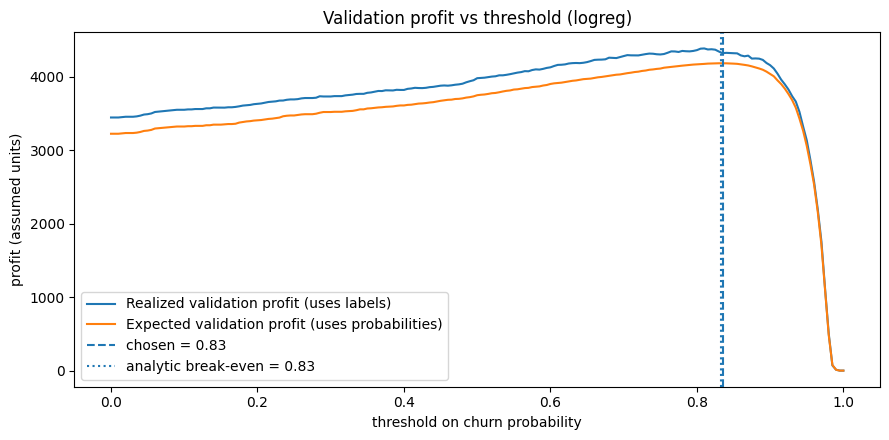

tiers: High >= 0.835 | Medium >= 0.716 and < 0.835 | Low < 0.716
tier-boundary check: OK


In [35]:
def ch_profit(y, p, t):
    """Retrospective realized profit: uses observed validation labels y."""
    contacted = p >= t
    return float((y[contacted] * CH_SAVE_RATE * CH_CUSTOMER_VALUE - CH_CONTACT_COST).sum())


def ch_expected_profit(p, t):
    """Expected profit at decision time, using predicted churn probabilities only."""
    contacted = p >= t
    per_contact_expected_value = p[contacted] * CH_SAVE_RATE * CH_CUSTOMER_VALUE - CH_CONTACT_COST
    return float(per_contact_expected_value.sum())

ch_grid_t = np.linspace(0, 1, 201)
ch_p_val = np.asarray(ch_P_va[CH_FINAL], dtype=float)
ch_prof_val = np.array([ch_profit(ch_yva, ch_p_val, t) for t in ch_grid_t])
ch_exp_prof_val = np.array([ch_expected_profit(ch_p_val, t) for t in ch_grid_t])
ch_t_emp = float(ch_grid_t[int(np.argmax(ch_prof_val))])
ch_t_expected = float(ch_grid_t[int(np.argmax(ch_exp_prof_val))])
ch_t_ana = float(np.clip(CH_CONTACT_COST / (CH_SAVE_RATE * CH_CUSTOMER_VALUE), 0.0, 1.0)) if CH_SAVE_RATE * CH_CUSTOMER_VALUE > 0 else 1.0

if CH_THRESHOLD_MODE == "expected":
    CH_THRESHOLD = ch_t_expected
elif CH_THRESHOLD_MODE == "empirical":
    CH_THRESHOLD = ch_t_emp
elif CH_THRESHOLD_MODE == "analytic":
    CH_THRESHOLD = ch_t_ana
else:
    raise ValueError("CH_THRESHOLD_MODE must be one of: 'expected', 'empirical', 'analytic'")

print(f"analytic break-even threshold: {ch_t_ana:.3f}")
print(f"validation empirical-profit threshold: {ch_t_emp:.3f} (retrospective profit {ch_prof_val.max():,.2f})")
print(f"validation expected-profit threshold: {ch_t_expected:.3f} (expected profit {ch_exp_prof_val.max():,.2f})")
print(f"threshold used ({CH_THRESHOLD_MODE}): {CH_THRESHOLD:.3f}")
if ch_exp_prof_val.max() <= 0:
    print("Expected profit is not positive for any threshold under these assumptions; contacting nobody may be preferable.")
if CH_THRESHOLD <= 0.01:
    print("Selected threshold is very low and may contact almost everyone; verify cost, value, and save-rate assumptions.")

plt.figure(figsize=(9, 4.5))
plt.plot(ch_grid_t, ch_prof_val, label="Realized validation profit (uses labels)")
plt.plot(ch_grid_t, ch_exp_prof_val, label="Expected validation profit (uses probabilities)")
plt.axvline(CH_THRESHOLD, ls="--", label=f"chosen = {CH_THRESHOLD:.2f}")
plt.axvline(ch_t_ana, ls=":", label=f"analytic break-even = {ch_t_ana:.2f}")
plt.title(f"Validation profit vs threshold ({CH_FINAL})")
plt.xlabel("threshold on churn probability")
plt.ylabel("profit (assumed units)")
plt.legend()
plt.tight_layout()
plt.show()

# Separate tier cut from the action threshold. Calculate it only from validation scores.
below_threshold = np.asarray(ch_p_val)[np.asarray(ch_p_val) < CH_THRESHOLD]
if len(below_threshold):
    CH_LOW_CUT = float(np.quantile(below_threshold, 0.50))
else:
    # Degenerate fallback: all validation scores are at/above the action threshold.
    CH_LOW_CUT = float(np.clip(CH_THRESHOLD - 1e-6, 0.0, 1.0))
CH_LOW_CUT = float(np.clip(CH_LOW_CUT, 0.0, CH_THRESHOLD))


def ch_tier_of(p):
    p = np.asarray(p)
    return np.where(p >= CH_THRESHOLD, "High",
                    np.where(p >= CH_LOW_CUT, "Medium", "Low"))


CH_ACTIONS = {
    "High": "Win-back offer (discount or free shipping) plus a reminder of viewed and carted items",
    "Medium": "Reminder email or push with recommended products, no discount",
    "Low": "No action, keep in the normal newsletter",
}
print(f"tiers: High >= {CH_THRESHOLD:.3f} | Medium >= {CH_LOW_CUT:.3f} and < {CH_THRESHOLD:.3f} | Low < {CH_LOW_CUT:.3f}")

# Sanity check: tier boundaries must be ordered, and the labels should be valid.
assert 0 <= CH_LOW_CUT <= CH_THRESHOLD <= 1
print("tier-boundary check: OK")


## 32. Churn test results
The test fold is used once. Baselines: a recency-only heuristic (recent visitors stay) and a random guess. The bootstrap resamples customers.

In [36]:
ch_tab = pd.DataFrame([ch_evaluate(n, ch_yte, ch_P_te[n], CH_THRESHOLD) for n in ch_cal]).set_index("model")
ch_heur = -ch_te["days_since_last_event"].to_numpy()
ap_heur = average_precision_score(1 - ch_yte, ch_heur)
ch_tab.loc["heuristic: recency only", ["PR-AUC retained", "lift vs base"]] = [ap_heur, ap_heur / (1 - ch_yte.mean())]
ch_tab.loc["random guess", ["PR-AUC retained", "lift vs base"]] = [1 - ch_yte.mean(), 1.0]
print(f"TEST (threshold {CH_THRESHOLD:.3f}, final model = {CH_FINAL})")
display(ch_tab)


def ch_bootstrap(y, scores, groups, n=500, seed=0):
    rng = np.random.default_rng(seed)
    by = pd.Series(np.arange(len(y))).groupby(np.asarray(groups)).indices
    keys = np.array(list(by.keys()))
    out = {k: [] for k in scores}
    for _ in range(n):
        ii = np.concatenate([by[k] for k in rng.choice(keys, size=len(keys), replace=True)])
        if 0 < y[ii].sum() < len(ii):
            for k, s in scores.items():
                out[k].append(ch_ap_retained(y[ii], s[ii]))
    return out


ch_scores = {n: ch_P_te[n] for n in ch_cal}
ch_scores["heuristic: recency only"] = 1 / (1 + np.exp(-(-ch_heur - np.median(-ch_heur))))
ch_boot = ch_bootstrap(ch_yte, ch_scores, ch_te["visitorid"].to_numpy())
rows = []
for k, v in ch_boot.items():
    lo, hi = np.percentile(v, [2.5, 97.5])
    rows.append({"model": k, "PR-AUC retained": ch_ap_retained(ch_yte, ch_scores[k]), "CI low": lo, "CI high": hi})
display(pd.DataFrame(rows).set_index("model"))
print(f"base rate of the retained class on test: {1 - ch_yte.mean():.4f}")

diff = np.array(ch_boot[CH_FINAL]) - np.array(ch_boot["heuristic: recency only"])
print(f"{CH_FINAL} minus recency heuristic: {diff.mean():+.4f}, 95% CI [{np.percentile(diff, 2.5):+.4f}, {np.percentile(diff, 97.5):+.4f}]")


def ch_business(name, mask):
    """Test-set retrospective profit; observed labels are used only for evaluation."""
    n = int(mask.sum())
    realized_profit = float((ch_yte[mask] * CH_SAVE_RATE * CH_CUSTOMER_VALUE - CH_CONTACT_COST).sum())
    expected_profit = float((ch_P_te[CH_FINAL][mask] * CH_SAVE_RATE * CH_CUSTOMER_VALUE - CH_CONTACT_COST).sum())
    return {"policy": name, "contacted": n, "share": n / len(ch_yte),
            "realized test profit (retrospective)": realized_profit,
            "expected test profit (probabilities)": expected_profit,
            "realized profit per customer": realized_profit / len(ch_yte),
            "expected profit per customer": expected_profit / len(ch_yte)}


ch_pf = ch_P_te[CH_FINAL]
ch_biz = pd.DataFrame([
    ch_business("contact nobody", np.zeros(len(ch_yte), bool)),
    ch_business("contact everybody", np.ones(len(ch_yte), bool)),
    ch_business("model, threshold 0.5", ch_pf >= 0.5),
    ch_business(f"model, cost threshold {CH_THRESHOLD:.2f}", ch_pf >= CH_THRESHOLD),
])
print("Business result on test under assumed costs. Realized profit is retrospective (uses labels); expected profit uses probabilities only.")
display(ch_biz)

# Risk-tier diagnostics: show actual sizes and observed churn rates; empty tiers remain visible.
ch_tier_summary = (
    pd.DataFrame({"tier": ch_tier_of(ch_pf), "actual_churn": np.asarray(ch_yte)})
      .groupby("tier")["actual_churn"].agg(customers="size", observed_churn_rate="mean")
      .reindex(["High", "Medium", "Low"])
)
print("Risk-tier diagnostics (test set; use for evaluation only, not threshold tuning):")
display(ch_tier_summary)
if (ch_tier_summary["customers"].fillna(0) == 0).any():
    print("WARNING: At least one risk tier is empty for this score distribution. Revisit the action threshold or tier-cut policy before operational use.")

TEST (threshold 0.835, final model = logreg)


,PR-AUC retained,lift vs base,PR-AUC churn,ROC-AUC,Brier,mean p,actual churn,precision@0.83,recall@0.83,F1@0.83
model,,,,,,,,,,
logreg,0.365667,5.508336,0.977361,0.803610,0.051504,0.923341,0.933616,0.961326,0.927421,0.944069
tree,0.328083,4.942181,0.972220,0.775745,0.053242,0.911545,0.933616,0.957097,0.951236,0.954158
lightgbm,0.355459,5.354561,0.974117,0.786446,0.052934,0.914725,0.933616,0.955131,0.958381,0.956753
mlp,0.351350,5.292662,0.976082,0.794631,0.052423,0.920621,0.933616,0.954192,0.959061,0.956620
heuristic: recency only,0.223188,3.362061,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random guess,0.066384,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,PR-AUC retained,CI low,CI high
model,,,
logreg,0.365667,0.326093,0.403661
tree,0.328083,0.289496,0.368028
lightgbm,0.355459,0.315468,0.395459
mlp,0.351350,0.312821,0.389352
heuristic: recency only,0.175761,0.157437,0.194712


base rate of the retained class on test: 0.0664
logreg minus recency heuristic: +0.1905, 95% CI [+0.1604, +0.2181]
Business result on test under assumed costs. Realized profit is retrospective (uses labels); expected profit uses probabilities only.


,policy,contacted,share,realized test profit (retrospective),expected test profit (probabilities),realized profit per customer,expected profit per customer
0,contact nobody,0,0.000000,0.0,0.000000,0.000000,0.000000
1,contact everybody,9445,1.000000,5683.0,5100.753499,0.601694,0.540048
2,"model, threshold 0.5",9259,0.980307,6175.0,5686.453017,0.653785,0.602060
3,"model, cost threshold 0.83",8507,0.900688,6533.0,6174.005831,0.691689,0.653680


Risk-tier diagnostics (test set; use for evaluation only, not threshold tuning):


,customers,observed_churn_rate
tier,,
High,8507,0.961326
Medium,471,0.798301
Low,467,0.565310


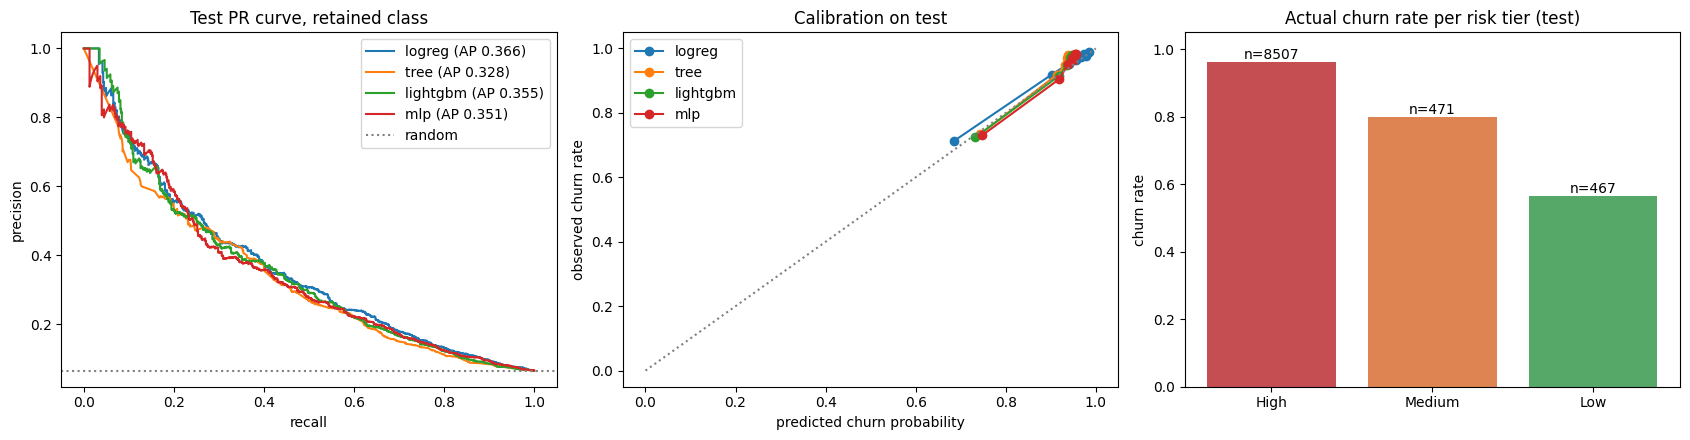

,size,mean
tier,,
High,8507,0.961326
Medium,471,0.798301
Low,467,0.565310


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for n in ch_cal:
    pr, rc, _ = precision_recall_curve(1 - ch_yte, 1 - ch_P_te[n])
    axes[0].plot(rc, pr, label=f"{n} (AP {ch_ap_retained(ch_yte, ch_P_te[n]):.3f})")
axes[0].axhline(1 - ch_yte.mean(), color="gray", ls=":", label="random")
axes[0].set(title="Test PR curve, retained class", xlabel="recall", ylabel="precision")
axes[0].legend()

for n in ch_cal:
    frac, mean_p = calibration_curve(ch_yte, ch_P_te[n], n_bins=8, strategy="quantile")
    axes[1].plot(mean_p, frac, marker="o", label=n)
axes[1].plot([0, 1], [0, 1], color="gray", ls=":")
axes[1].set(title="Calibration on test", xlabel="predicted churn probability", ylabel="observed churn rate")
axes[1].legend()

order = ["High", "Medium", "Low"]
ch_tiers = pd.DataFrame({"tier": ch_tier_of(ch_pf), "churn": ch_yte}).groupby("tier")["churn"].agg(["size", "mean"]).reindex(order)
plot_tab = ch_tiers.fillna(0)
axes[2].bar(order, plot_tab["mean"], color=["#c44e52", "#dd8452", "#55a868"])
for i, (s, m) in enumerate(zip(plot_tab["size"], plot_tab["mean"])):
    axes[2].text(i, m, f"n={int(s)}", ha="center", va="bottom")
axes[2].set(title="Actual churn rate per risk tier (test)", ylabel="churn rate", ylim=(0, 1.05))
plt.tight_layout()
plt.show()
display(ch_tiers)

## 32A. Budget-constrained retention policies (top 10%, 20%, 30%)

The cost-based threshold can still contact most customers when the churn rate is very high. This section compares budget-limited campaigns. For each budget, it selects the highest-risk customers **by model score only**; labels are used only afterward to evaluate realized test profit. The test labels are never used to choose a model or tune the threshold.

This is an offline policy comparison, not proof that an offer will cause a customer to stay. `CH_SAVE_RATE` is an assumption; a randomized retention experiment is needed to estimate causal uplift.


In [38]:
def ch_evaluate_top_fraction(y, p, fraction, name):
    """Select the top-scored fraction; labels are used only for post-hoc evaluation."""
    y = np.asarray(y).astype(float)
    p = np.asarray(p, dtype=float)
    if len(y) != len(p):
        raise ValueError("y and p must have the same length")
    if not 0 < fraction <= 1:
        raise ValueError("fraction must be in (0, 1]")
    n_contact = int(np.ceil(len(p) * fraction))
    # Stable ranking ensures exactly n_contact rows are selected, including tied scores.
    order = np.argsort(-p, kind="mergesort")
    contacted = np.zeros(len(p), dtype=bool)
    contacted[order[:n_contact]] = True
    realized = float((y[contacted] * CH_SAVE_RATE * CH_CUSTOMER_VALUE - CH_CONTACT_COST).sum())
    expected = float((p[contacted] * CH_SAVE_RATE * CH_CUSTOMER_VALUE - CH_CONTACT_COST).sum())
    return {
        "policy": name,
        "target_fraction": float(fraction),
        "contacted": int(contacted.sum()),
        "actual_contact_share": float(contacted.mean()),
        "score_cutoff_test_population": float(np.min(p[contacted])) if contacted.any() else np.nan,
        "expected_profit_test": expected,
        "realized_profit_test_retrospective": realized,
        "expected_profit_per_test_customer": expected / len(y),
        "realized_profit_per_test_customer": realized / len(y),
        "observed_churn_rate_contacted": float(y[contacted].mean()) if contacted.any() else np.nan,
        "mean_predicted_churn_contacted": float(p[contacted].mean()) if contacted.any() else np.nan,
    }

ch_budget_rows = []
ch_test_scores_final = np.asarray(ch_P_te[CH_FINAL], dtype=float)
for fraction in (0.10, 0.20, 0.30):
    ch_budget_rows.append(ch_evaluate_top_fraction(
        ch_yte, ch_test_scores_final, fraction, f"top_{int(fraction * 100)}pct_risk"
    ))
ch_budget_policy_results = pd.DataFrame(ch_budget_rows).set_index("policy")
print("Budget-constrained test policies. Realized profit is retrospective; expected profit uses scores only.")
display(ch_budget_policy_results)

# Compare the budget policies with the threshold policy already selected on validation.
ch_threshold_mask = ch_test_scores_final >= CH_THRESHOLD
ch_threshold_expected = ch_expected_profit(ch_test_scores_final, CH_THRESHOLD)
ch_threshold_realized = ch_profit(ch_yte, ch_test_scores_final, CH_THRESHOLD)
print(f"Selected validation threshold policy: contacts={int(ch_threshold_mask.sum())} "
      f"({ch_threshold_mask.mean():.1%}); expected test profit={ch_threshold_expected:,.2f}; "
      f"retrospective realized test profit={ch_threshold_realized:,.2f}")

# Budget policies can have lower total profit but substantially lower campaign spend.
# Do not pick the winning policy from this test table; use validation/business constraints, then report test once.


Budget-constrained test policies. Realized profit is retrospective; expected profit uses scores only.


,target_fraction,contacted,actual_contact_share,score_cutoff_test_population,expected_profit_test,realized_profit_test_retrospective,expected_profit_per_test_customer,realized_profit_per_test_customer,observed_churn_rate_contacted,mean_predicted_churn_contacted
policy,,,,,,,,,,
top_10pct_risk,0.1,945,0.100053,0.982901,862.319659,867.0,0.091299,0.091795,0.986243,0.985418
top_20pct_risk,0.2,1889,0.200000,0.978748,1697.787554,1697.0,0.179755,0.179672,0.983060,0.983129
top_30pct_risk,0.3,2834,0.300053,0.974159,2509.190376,2528.0,0.265663,0.267655,0.982004,0.980898


Selected validation threshold policy: contacts=8507 (90.1%); expected test profit=6,174.01; retrospective realized test profit=6,533.00


## 33. Churn explanations and scoring function
Exact TreeSHAP for LightGBM, linear contributions for Logistic Regression and path contributions for the tree. A positive value pushes the customer towards churn. The explanations belong to the raw model; the probability shown to the user comes from its calibrated version.

Ten highest-risk customers on the test fold (logreg):


,visitorid,churn_proba,tier,action,reason_1,reason_2,reason_3
697,109717,0.994198,High,Win-back offer (discount or free shipping) plu...,days since last activity = 101.0 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
4977,754358,0.994065,High,Win-back offer (discount or free shipping) plu...,days since last activity = 100.2 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.5 (lowers risk)
2721,409939,0.993825,High,Win-back offer (discount or free shipping) plu...,days since last activity = 105.0 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
8848,1320501,0.993757,High,Win-back offer (discount or free shipping) plu...,days since last activity = 103.3 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
8611,1286040,0.993715,High,Win-back offer (discount or free shipping) plu...,days since last activity = 102.2 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
7016,1049595,0.993710,High,Win-back offer (discount or free shipping) plu...,days since last activity = 105.5 (raises risk),purchase rate (purchases per interaction) = 1....,days since first activity = 105.5 (lowers risk)
5822,874668,0.993553,High,Win-back offer (discount or free shipping) plu...,days since last activity = 98.4 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
4523,682501,0.993532,High,Win-back offer (discount or free shipping) plu...,days since last activity = 97.9 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
3342,503542,0.993490,High,Win-back offer (discount or free shipping) plu...,days since last activity = 96.9 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)
2699,406338,0.993421,High,Win-back offer (discount or free shipping) plu...,days since last activity = 95.4 (raises risk),purchase rate (purchases per interaction) = 1....,interactions per visit = 1.0 (lowers risk)


Ten lowest-risk customers:


,visitorid,churn_proba,tier,action,reason_1,reason_2,reason_3
7529,1126569,0.017880,Low,"No action, keep in the normal newsletter",days since last activity = 0.2 (lowers risk),distinct products seen = 421.0 (lowers risk),orders placed = 7.0 (raises risk)
7795,1165148,0.017878,Low,"No action, keep in the normal newsletter",days since last activity = 0.0 (lowers risk),orders placed = 14.0 (raises risk),distinct products seen = 413.0 (lowers risk)
5966,895999,0.015608,Low,"No action, keep in the normal newsletter",days since last activity = 0.1 (lowers risk),orders placed = 18.0 (raises risk),"distinct products seen = 1,227.0 (lowers risk)"
4596,693709,0.015512,Low,"No action, keep in the normal newsletter",days since last activity = 0.3 (lowers risk),distinct products seen = 182.0 (lowers risk),days between first and last purchase = 97.0 (l...
3428,518659,0.014927,Low,"No action, keep in the normal newsletter",days since last activity = 0.2 (lowers risk),distinct products seen = 602.0 (lowers risk),orders placed = 9.0 (raises risk)
9426,1403769,0.014792,Low,"No action, keep in the normal newsletter",days since last activity = 0.2 (lowers risk),distinct products seen = 210.0 (lowers risk),days between first and last purchase = 90.2 (l...
1505,229157,0.014280,Low,"No action, keep in the normal newsletter",days since last activity = 0.1 (lowers risk),distinct products seen = 689.0 (lowers risk),active days = 61.0 (lowers risk)
8981,1336835,0.013907,Low,"No action, keep in the normal newsletter",days since last activity = 0.5 (lowers risk),distinct products seen = 316.0 (lowers risk),active days = 61.0 (lowers risk)
2115,316850,0.008804,Low,"No action, keep in the normal newsletter",days since last activity = 0.1 (lowers risk),distinct products seen = 851.0 (lowers risk),orders placed = 9.0 (raises risk)
5487,825321,0.008033,Low,"No action, keep in the normal newsletter",days since last activity = 0.2 (lowers risk),distinct products seen = 565.0 (lowers risk),active days = 73.0 (lowers risk)


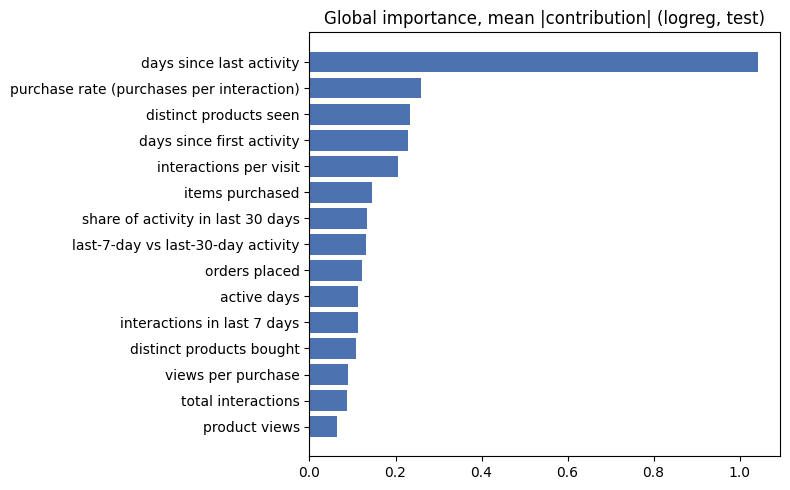

In [39]:
def ch_tree_contrib(model, X):
    t = model.tree_
    v = t.value[:, 0, :]
    p1 = v[:, 1] / v.sum(axis=1)
    paths = model.decision_path(X.to_numpy())
    out = np.zeros((X.shape[0], X.shape[1]))
    for r in range(X.shape[0]):
        nodes = paths.indices[paths.indptr[r]:paths.indptr[r + 1]]
        for a, b in zip(nodes[:-1], nodes[1:]):
            out[r, t.feature[a]] += p1[b] - p1[a]
    return out


def ch_contributions(name, model, X):
    if name == "lightgbm":
        return model.booster_.predict(X, pred_contrib=True)[:, :-1]
    if name == "logreg":
        return model[:-1].transform(X) * model[-1].coef_[0]
    if name == "mlp":
        f = lambda a: model.predict_proba(pd.DataFrame(a, columns=CH_FEATURES))[:, 1]
        bg = shap.kmeans(ch_Xtr, 30)
        return np.asarray(shap.KernelExplainer(f, bg).shap_values(X, nsamples=100, silent=True))
    return ch_tree_contrib(model, X)


def ch_reasons(contrib, X, top_k=3):
    out = []
    for r in range(len(X)):
        idx = np.argsort(-np.abs(contrib[r]))[:top_k]
        out.append([f"{CH_FEATURE_TEXT.get(CH_FEATURES[j], CH_FEATURES[j])} = {X.iloc[r, j]:,.1f} "
                    f"({'raises' if contrib[r, j] > 0 else 'lowers'} risk)" for j in idx])
    return out


def ch_score_users(users, cutoff, top_k=3):
    feats = ch_build_features(cutoff, users)
    if feats.empty:
        return pd.DataFrame(columns=["visitorid", "churn_proba", "tier", "action"] + [f"reason_{k + 1}" for k in range(top_k)])
    X = feats[CH_FEATURES]
    p = ch_cal[CH_FINAL].predict_proba(X)[:, 1]
    rs = ch_reasons(ch_contributions(CH_FINAL, ch_raw[CH_FINAL], X), X, top_k)
    out = pd.DataFrame({"visitorid": feats["visitorid"], "churn_proba": p, "tier": ch_tier_of(p)})
    out["action"] = out["tier"].map(CH_ACTIONS)
    for k in range(top_k):
        out[f"reason_{k + 1}"] = [r[k] for r in rs]
    return out


ch_scored = ch_score_users(ch_te["visitorid"].to_numpy(), ch_te["cutoff"].iloc[0]).sort_values("churn_proba", ascending=False)
print(f"Ten highest-risk customers on the test fold ({CH_FINAL}):")
display(ch_scored.head(10))
print("Ten lowest-risk customers:")
display(ch_scored.tail(10))

ch_C = ch_contributions(CH_FINAL, ch_raw[CH_FINAL], ch_Xte)
imp = pd.Series(np.abs(ch_C).mean(axis=0), index=CH_FEATURES).sort_values().tail(15)
plt.figure(figsize=(8, 5))
plt.barh([CH_FEATURE_TEXT.get(f, f) for f in imp.index], imp.values, color="#4c72b0")
plt.title(f"Global importance, mean |contribution| ({CH_FINAL}, test)")
plt.tight_layout()
plt.show()

if CH_FINAL == "lightgbm":
    try:
        shap.summary_plot(ch_C, ch_Xte, show=False, max_display=15)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("SHAP summary plot skipped:", type(e).__name__)

## 33A. Churn neural network: explainability
SHAP (KernelExplainer) on the raw MLP, plus permutation importance. Positive value = pushes towards churn.

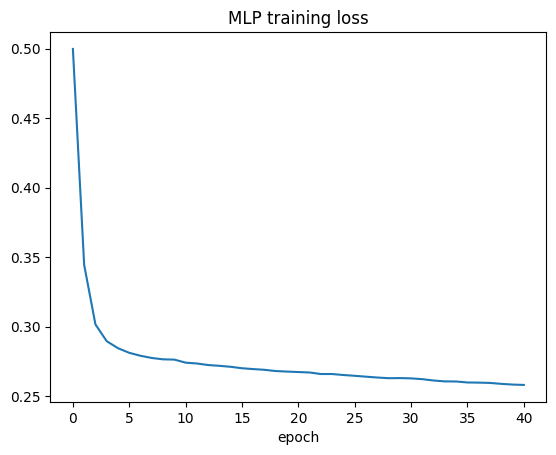

In [40]:
nn = ch_raw["mlp"]
plt.plot(nn[-1].loss_curve_); plt.title("MLP training loss"); plt.xlabel("epoch"); plt.show()

idx = np.random.default_rng(CH_SEED).choice(len(ch_Xte), 500, replace=False)
Xs = ch_Xte.iloc[idx]
f = lambda a: nn.predict_proba(pd.DataFrame(a, columns=CH_FEATURES))[:, 1]
expl = shap.KernelExplainer(f, shap.kmeans(ch_Xtr, 30))
sv = np.asarray(expl.shap_values(Xs, nsamples=200, silent=True))

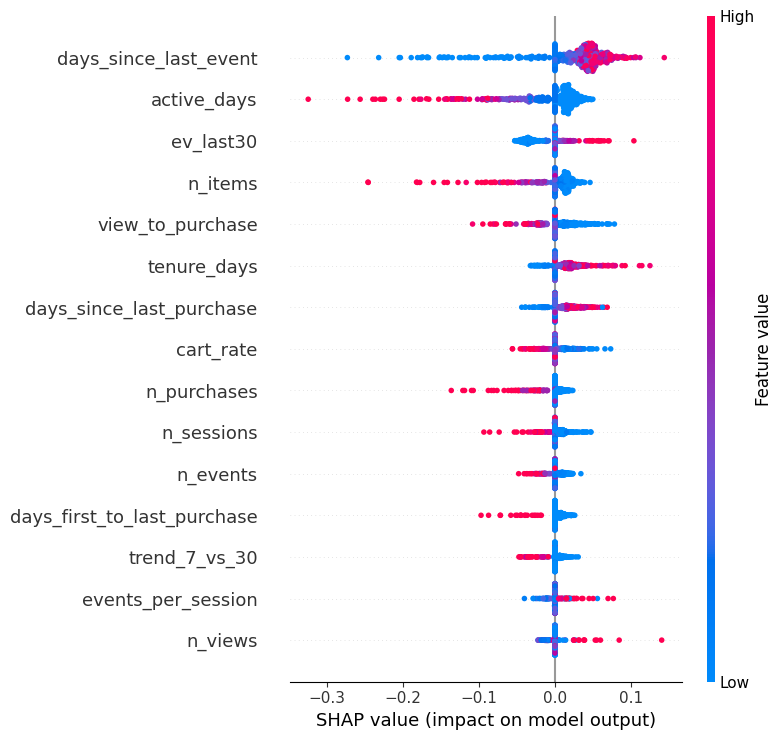

,mean |SHAP|
days_since_last_event,0.047649
active_days,0.031809
ev_last30,0.023049
n_items,0.018373
view_to_purchase,0.017562
tenure_days,0.017286
days_since_last_purchase,0.014723
cart_rate,0.008656
n_purchases,0.008291
n_sessions,0.007280


In [41]:
shap.summary_plot(sv, Xs, show=False, max_display=15)
plt.tight_layout(); plt.show()

nn_imp = pd.Series(np.abs(sv).mean(0), index=CH_FEATURES).sort_values(ascending=False)
display(nn_imp.head(10).to_frame("mean |SHAP|"))

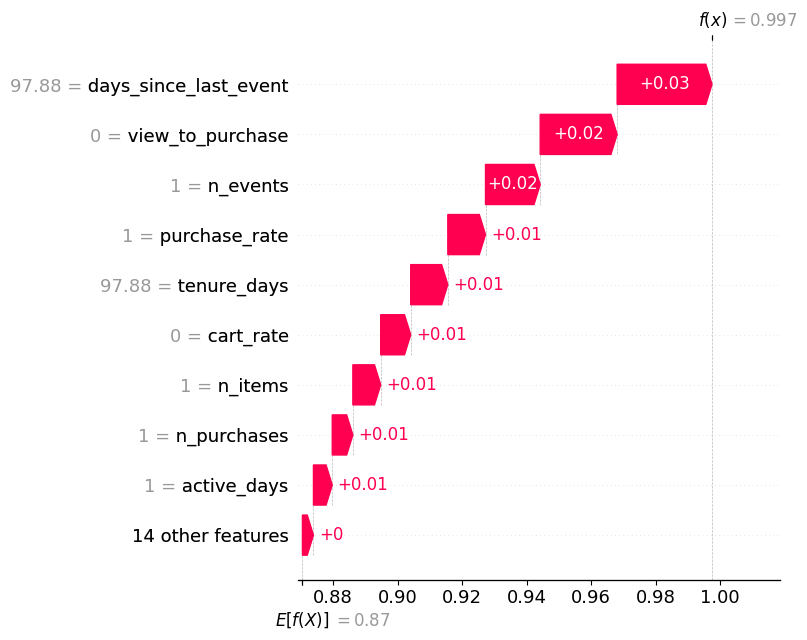

In [42]:
i = int(np.argmax(f(Xs.to_numpy())))
shap.waterfall_plot(shap.Explanation(values=sv[i], base_values=float(np.ravel(expl.expected_value)[0]),
                                     data=Xs.iloc[i].values, feature_names=CH_FEATURES), show=False)
plt.tight_layout(); plt.show()

In [43]:
lr_imp = pd.Series(np.abs(ch_contributions("logreg", ch_raw["logreg"], Xs)).mean(0), index=CH_FEATURES)
print("Spearman of feature importance, NN vs LogReg:", round(nn_imp.rank().corr(lr_imp.rank()), 3))

Spearman of feature importance, NN vs LogReg: 0.229


In [44]:
from sklearn.inspection import permutation_importance
scorer = lambda est, X, y: ch_ap_retained(y, est.predict_proba(X)[:, 1])
pi = permutation_importance(nn, ch_Xte, ch_yte, scoring=scorer, n_repeats=5, random_state=CH_SEED)
display(pd.Series(pi.importances_mean, index=CH_FEATURES).sort_values(ascending=False).head(10).to_frame("PR-AUC drop"))

,PR-AUC drop
days_since_last_event,0.099087
active_days,0.088547
n_items,0.065006
view_to_purchase,0.028795
ev_last30,0.014950
n_purchases,0.012040
n_events,0.010051
carts_last30,0.009888
n_sessions,0.008524
ev_last7,0.006876


## 34. Churn sanity checks
1. **Label windows do not overlap across folds:** the last label window of train ends before the first validation cut-off, and the same for validation and test.
2. **No future information in features:** the features of a cut-off are recomputed after scrambling every event after the cut-off; they must not change.
3. **Shuffled labels:** a model trained on shuffled train labels should score at the base rate on validation. A clearly higher score would point to leakage.
4. **Customer overlap:** share of test customers that also appear in the train fold (the same person can be in several folds, which is normal for churn but should be known).

In [45]:
H_ms = CH_H * CH_DAY_MS
cut_by = {f: sorted(set(ch_labels.loc[ch_labels["fold"] == f, "cutoff"])) for f in CH_FOLDS}
assert max(cut_by["train"]) + H_ms <= min(cut_by["validation"]), "train label window runs into validation"
assert max(cut_by["validation"]) + H_ms <= min(cut_by["test"]), "validation label window runs into test"
print("1. label windows are separated: OK")

T_chk = int(cut_by["test"][0])
users_chk = ch_te["visitorid"].to_numpy()[:2000]
iT = np.searchsorted(CH_TS, T_chk, "left")
rng = np.random.default_rng(0)
c_scr, i_scr, tx_scr = CH_C.copy(), CH_I.copy(), CH_TX.copy()
c_scr[iT:] = rng.integers(0, 3, len(c_scr) - iT)
i_scr[iT:] = rng.permutation(i_scr[iT:])
tx_scr[iT:] = rng.permutation(tx_scr[iT:])
f_ref = ch_build_features(T_chk, users_chk).sort_values("visitorid").reset_index(drop=True)
f_scr = ch_build_features(T_chk, users_chk, c=c_scr, i=i_scr, tx=tx_scr).sort_values("visitorid").reset_index(drop=True)
pd.testing.assert_frame_equal(f_ref, f_scr)
print("2. features ignore everything after the cut-off: OK")

rng = np.random.default_rng(CH_SEED)
rows = []
for rep in range(3):
    y_shuf = rng.permutation(ch_ytr)
    m = ch_make_model("lightgbm", ch_best["lightgbm"]).fit(ch_Xtr, y_shuf)
    rows.append(ch_ap_retained(ch_yva, m.predict_proba(ch_Xva)[:, 1]))
real_ap = ch_ap_retained(ch_yva, ch_P_va["lightgbm"])
print(f"3. shuffled-label PR-AUC (retained) on validation: {np.mean(rows):.4f} +/- {np.std(rows):.4f} | base rate {1 - ch_yva.mean():.4f} | real model {real_ap:.4f}")

overlap = np.isin(ch_te["visitorid"], ch_tr["visitorid"]).mean()
print(f"4. test customers that also appear in the train fold: {overlap:.1%}")

ch_checks = pd.DataFrame({
    "check": ["label windows separated", "features ignore the future", "shuffled-label PR-AUC near base rate", "test customers also in train"],
    "result": ["pass", "pass", f"{np.mean(rows):.4f} vs base {1 - ch_yva.mean():.4f}", f"{overlap:.1%}"],
})
display(ch_checks)

1. label windows are separated: OK
2. features ignore everything after the cut-off: OK
3. shuffled-label PR-AUC (retained) on validation: 0.0894 +/- 0.0178 | base rate 0.0830 | real model 0.3939
4. test customers that also appear in the train fold: 45.1%


,check,result
0,label windows separated,pass
1,features ignore the future,pass
2,shuffled-label PR-AUC near base rate,0.0894 vs base 0.0830
3,test customers also in train,45.1%


## 35. Churn summary

In [46]:
summary_rows = []
for n in ch_cal:
    summary_rows.append({"model": n, "validation PR-AUC retained": ch_val_tab.loc[n, "PR-AUC retained"],
                         "test PR-AUC retained": ch_tab.loc[n, "PR-AUC retained"], "test lift vs base": ch_tab.loc[n, "lift vs base"],
                         "test ROC-AUC": ch_tab.loc[n, "ROC-AUC"], "test Brier": ch_tab.loc[n, "Brier"]})
for n in ["heuristic: recency only", "random guess"]:
    summary_rows.append({"model": n, "test PR-AUC retained": ch_tab.loc[n, "PR-AUC retained"], "test lift vs base": ch_tab.loc[n, "lift vs base"]})
display(pd.DataFrame(summary_rows).set_index("model"))
print("definition:", CH_DEFINITION)
print(f"final model: {CH_FINAL} | threshold {CH_THRESHOLD:.3f} | low cut {CH_LOW_CUT:.3f}")

if CH_SAVE_BUNDLE:
    out_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
    joblib.dump({
        "final_model": CH_FINAL, "calibrated_model": ch_cal[CH_FINAL], "raw_model": ch_raw[CH_FINAL],
        "features": CH_FEATURES, "feature_text": CH_FEATURE_TEXT, "threshold": CH_THRESHOLD, "low_cut": CH_LOW_CUT,
        "actions": CH_ACTIONS, "definition": CH_DEFINITION, "best_params": ch_best,
        "costs": {"contact_cost": CH_CONTACT_COST, "customer_value": CH_CUSTOMER_VALUE, "save_rate": CH_SAVE_RATE},
    }, out_dir / "churn_model.joblib")
    print("saved:", out_dir / "churn_model.joblib")

,validation PR-AUC retained,test PR-AUC retained,test lift vs base,test ROC-AUC,test Brier
model,,,,,
logreg,0.423156,0.365667,5.508336,0.803610,0.051504
tree,0.372261,0.328083,4.942181,0.775745,0.053242
lightgbm,0.393898,0.355459,5.354561,0.786446,0.052934
mlp,0.401651,0.351350,5.292662,0.794631,0.052423
heuristic: recency only,NaN,0.223188,3.362061,NaN,NaN
random guess,NaN,0.066384,1.000000,NaN,NaN


definition: customer = bought before the cut-off; churn = 1 means: no event at all (stopped visiting) in the 30 days after the cut-off
final model: logreg | threshold 0.835 | low cut 0.716
saved: /kaggle/working/churn_model.joblib


## What the churn results mean
- **Definition:** churn here is operational. `visitorid` is anonymous, so "no activity" can also mean a new cookie or device. If the chosen label is not `purchase`, churn means "stopped visiting or showing purchase intent", not only "stopped buying".
- **Metric:** compare PR-AUC of the retained class with the base rate (the `lift vs base` column) and with the recency heuristic. A high PR-AUC of the churn class means nothing when most rows are churn.
- **Calibration and drift:** the churn rate usually rises from train to test. Compare `mean p` with `actual churn` and read the calibration plot before trusting the probabilities as absolute numbers.
- **Threshold:** it comes from three assumed business numbers. With real values the best policy can change, from contacting everybody to contacting only the High tier.
- **Limits:** one dataset of about four and a half months, anonymous visitors, a small retained class, and offline evaluation only. Differences between models that sit inside the bootstrap interval are not real differences.

### Interpretation and limitations (updated)
- The label is operational and depends on the selected population, label, and horizon shown above; anonymous `visitorid` values do not prove real-world customer identity.
- Validation-selected thresholds can overfit a single validation window. Compare the empirical threshold with the analytic break-even threshold and the probability-based expected-profit curve.
- Test realized profit is a retrospective estimate using observed labels; it is not a guaranteed future profit. Expected profit uses predicted probabilities and still depends on the assumed save rate, contact cost, and customer value.
- High/Medium/Low tiers use distinct ordered cutoffs derived from validation predictions. Always inspect the resulting tier counts and observed churn rate by tier before using them operationally.


## 36. MLflow tracking + export all trained models

This section runs **after** the evaluation cells so the reported metrics and selected models are already available.

It creates:
- A local MLflow tracking database (`mlflow.db`, SQLite).
- One MLflow run for each trained Purchase/Discovery ranker and each raw/calibrated Churn model.
- Individual `.joblib` exports for all fitted models, plus a bundle containing model metadata, features, thresholds, definitions, and ensemble settings.
- CSV/JSON metrics and a ZIP package for portability.

**Note:** MLflow logs the trained model files as artifacts; the `.joblib` exports are the portable source of truth. Run this cell after running the notebook from the top, because it relies on fitted models and result tables from earlier sections.

In [47]:
import json
import os
import shutil
import sqlite3
import zipfile
import platform
from datetime import datetime, timezone
from pathlib import Path
import sklearn
import mlflow
import joblib

# Use Kaggle working directory when available; otherwise keep artifacts in ./smartcart_artifacts.
EXPORT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
EXPORT_DIR = EXPORT_ROOT / "smartcart_model_exports"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = EXPORT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# SQLite-backed MLflow tracking database.
MLFLOW_DB = EXPORT_ROOT / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.resolve().as_posix()}")
mlflow.set_experiment("SmartCart-RetailRocket")

def _safe_name(value):
    return "".join(ch if ch.isalnum() or ch in "-_." else "_" for ch in str(value))

def _save_json(obj, path):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=str)

export_manifest = []
logged_run_count = 0

def _log_model_artifact(run_name, model_key, model_obj, task_name, model_kind,
                        params=None, metrics=None, extra_metadata=None):
    global logged_run_count
    model_file = MODEL_DIR / f"{_safe_name(model_key)}.joblib"
    joblib.dump(model_obj, model_file)

    meta = {
        "model_key": model_key,
        "task": task_name,
        "model_kind": model_kind,
        "file": str(model_file.name),
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
    }
    if params:
        meta["params"] = params
    if extra_metadata:
        meta.update(extra_metadata)
    meta_file = MODEL_DIR / f"{_safe_name(model_key)}.json"
    _save_json(meta, meta_file)

    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({
            "project": "SmartCart",
            "task": task_name,
            "model_key": model_key,
            "model_kind": model_kind,
        })
        mlflow.log_param("model_key", model_key)
        mlflow.log_param("model_kind", model_kind)
        if params:
            for k, v in params.items():
                if isinstance(v, (str, int, float, bool)) or v is None:
                    mlflow.log_param(f"param_{k}", str(v) if v is None else v)
        if metrics:
            for k, v in metrics.items():
                try:
                    if v is not None and np.isfinite(float(v)):
                        mlflow.log_metric(_safe_name(k), float(v))
                except (TypeError, ValueError):
                    pass
        mlflow.log_artifact(str(model_file), artifact_path="model_files")
        mlflow.log_artifact(str(meta_file), artifact_path="metadata")

        # Also log a native MLflow sklearn model when supported by this estimator/version.
        # The joblib artifact above is always logged, even if this flavor conversion fails.
        try:
            mlflow.sklearn.log_model(model_obj, artifact_path="sklearn_model")
        except Exception as exc:
            mlflow.set_tag("sklearn_flavor_log_status", f"joblib_only: {type(exc).__name__}")

    logged_run_count += 1
    export_manifest.append(meta)

# Export all fitted Purchase Prediction and Discovery rankers.
ranker_metrics_rows = []
for task_var, task_label in [(purchase_task, "purchase"), (discovery_task, "discovery")]:
    for model_name, fitted_model in task_var.get("models", {}).items():
        val_ndcg = task_var.get("ranker_val", {}).get(model_name)
        test_ndcg = None
        try:
            tdf = task_var["test_tables"]["all"].set_index("Model")
            test_ndcg = float(tdf.loc[model_name, f"NDCG@{K}"])
        except Exception:
            pass
        params = task_var.get("params", {}).get(model_name, {})
        metrics = {"validation_ndcg_at_10": val_ndcg, "test_ndcg_at_10": test_ndcg}
        _log_model_artifact(
            run_name=f"{task_label}_{model_name}",
            model_key=f"{task_label}_{model_name}",
            model_obj=fitted_model,
            task_name=task_label,
            model_kind="ranker",
            params=params,
            metrics=metrics,
            extra_metadata={
                "features": task_var.get("features", []),
                "validation_ndcg_at_10": val_ndcg,
                "test_ndcg_at_10": test_ndcg,
            },
        )
        ranker_metrics_rows.append({
            "task": task_label, "model": model_name,
            "validation_ndcg_at_10": val_ndcg, "test_ndcg_at_10": test_ndcg,
            "params": json.dumps(params, default=str),
        })

# Log budget-policy comparison separately; metrics are test diagnostics, not model-selection criteria.
if "ch_budget_policy_results" in globals():
    with mlflow.start_run(run_name="churn_budget_policy_comparison"):
        mlflow.set_tags({"project": "SmartCart", "task": "churn_business_policy", "split": "test_diagnostic"})
        mlflow.log_param("selected_churn_model", str(CH_FINAL))
        mlflow.log_param("threshold_mode", str(CH_THRESHOLD_MODE))
        mlflow.log_param("selected_threshold", float(CH_THRESHOLD))
        for policy_name, policy_row in ch_budget_policy_results.iterrows():
            prefix = _safe_name(policy_name)
            for metric_name in ["target_fraction", "actual_contact_share", "expected_profit_test",
                                "realized_profit_test_retrospective", "expected_profit_per_test_customer",
                                "realized_profit_per_test_customer", "observed_churn_rate_contacted",
                                "mean_predicted_churn_contacted"]:
                value = policy_row.get(metric_name)
                if value is not None and pd.notna(value):
                    mlflow.log_metric(f"{prefix}_{metric_name}", float(value))

# Export all raw and calibrated churn models, not only the selected model.
for model_name in ch_raw:
    val_row = ch_val_tab.loc[model_name].to_dict()
    test_row = ch_tab.loc[model_name].to_dict()
    common_metrics = {
        "validation_pr_auc_retained": val_row.get("PR-AUC retained"),
        "validation_roc_auc": val_row.get("ROC-AUC"),
        "validation_brier": val_row.get("Brier"),
        "test_pr_auc_retained": test_row.get("PR-AUC retained"),
        "test_roc_auc": test_row.get("ROC-AUC"),
        "test_brier": test_row.get("Brier"),
    }
    _log_model_artifact(
        run_name=f"churn_{model_name}_raw",
        model_key=f"churn_{model_name}_raw",
        model_obj=ch_raw[model_name],
        task_name="churn",
        model_kind="raw_classifier",
        params=ch_best.get(model_name, {}),
        metrics=common_metrics,
        extra_metadata={"features": CH_FEATURES, "definition": CH_DEFINITION},
    )
    _log_model_artifact(
        run_name=f"churn_{model_name}_calibrated",
        model_key=f"churn_{model_name}_calibrated",
        model_obj=ch_cal[model_name],
        task_name="churn",
        model_kind="calibrated_classifier",
        params=ch_best.get(model_name, {}),
        metrics=common_metrics,
        extra_metadata={
            "features": CH_FEATURES, "definition": CH_DEFINITION,
            "selected_final_model": model_name == CH_FINAL,
            "threshold": float(CH_THRESHOLD),
            "threshold_mode": CH_THRESHOLD_MODE,
            "low_cut": float(CH_LOW_CUT),
        },
    )

# Bundle: inference-ready churn models + decision settings + recommender model references/configs.
churn_bundle = {
    "selected_model_name": CH_FINAL,
    "selected_calibrated_model": ch_cal[CH_FINAL],
    "selected_raw_model": ch_raw[CH_FINAL],
    "all_calibrated_models": ch_cal,
    "all_raw_models": ch_raw,
    "features": CH_FEATURES,
    "feature_text": CH_FEATURE_TEXT,
    "threshold": float(CH_THRESHOLD),
    "threshold_mode": CH_THRESHOLD_MODE,
    "expected_profit_threshold_validation": float(ch_t_expected),
    "empirical_profit_threshold_validation": float(ch_t_emp),
    "analytic_break_even_threshold": float(ch_t_ana),
    "low_cut": float(CH_LOW_CUT),
    "actions": CH_ACTIONS,
    "definition": CH_DEFINITION,
    "best_params": ch_best,
    "costs": {
        "contact_cost": CH_CONTACT_COST,
        "customer_value": CH_CUSTOMER_VALUE,
        "save_rate": CH_SAVE_RATE,
    },
}
joblib.dump(churn_bundle, EXPORT_DIR / "churn_all_models_bundle.joblib")

# Save recommendation task metadata and ensemble configuration; ensembles are scoring recipes,
# so their component estimators are exported individually above.
recommendation_bundle = {}
for task_var, task_label in [(purchase_task, "purchase"), (discovery_task, "discovery")]:
    recommendation_bundle[task_label] = {
        "features": task_var.get("features", []),
        "model_names": list(task_var.get("models", {}).keys()),
        "params": task_var.get("params", {}),
        "ranker_validation_scores": task_var.get("ranker_val", {}),
        "ranked_models": task_var.get("ranked_models", []),
        "ensembles": task_var.get("ensembles", {}),
        "final_model": task_var.get("final"),
        "explain_model": task_var.get("explain"),
        "hybrid_weights": task_var.get("hybrid_weights", {}),
        "candidate_sources": task_var.get("names", []),
    }
_save_json(recommendation_bundle, EXPORT_DIR / "recommendation_config.json")

_save_json(export_manifest, EXPORT_DIR / "model_manifest.json")
pd.DataFrame(export_manifest).to_csv(EXPORT_DIR / "model_manifest.csv", index=False)
pd.DataFrame(ranker_metrics_rows).to_csv(EXPORT_DIR / "recommendation_model_metrics.csv", index=False)

# Export the key churn evaluation tables.
if "ch_budget_policy_results" in globals():
    ch_budget_policy_results.to_csv(EXPORT_DIR / "churn_budget_policy_comparison.csv")

ch_val_tab.to_csv(EXPORT_DIR / "churn_validation_metrics.csv")
ch_tab.to_csv(EXPORT_DIR / "churn_test_metrics.csv")

# Save environment and reproducibility metadata.
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "mlflow": mlflow.__version__,
    "mlflow_tracking_uri": mlflow.get_tracking_uri(),
    "selected_churn_model": CH_FINAL,
    "churn_threshold": float(CH_THRESHOLD),
    "churn_threshold_mode": CH_THRESHOLD_MODE,
    "churn_expected_profit_threshold_validation": float(ch_t_expected),
    "churn_empirical_profit_threshold_validation": float(ch_t_emp),
    "churn_analytic_break_even_threshold": float(ch_t_ana),
    "churn_low_cut": float(CH_LOW_CUT),
    "churn_definition": CH_DEFINITION,
    "mlflow_runs_logged": logged_run_count,
}
_save_json(environment, EXPORT_DIR / "environment.json")

# Create a consistent SQLite snapshot of the MLflow tracking DB.
db_snapshot = EXPORT_DIR / "mlflow.db"
if MLFLOW_DB.exists():
    src_conn = sqlite3.connect(str(MLFLOW_DB))
    dst_conn = sqlite3.connect(str(db_snapshot))
    try:
        src_conn.backup(dst_conn)
    finally:
        dst_conn.close()
        src_conn.close()

# Package all model files, configs, metrics, and the database snapshot.
zip_path = EXPORT_ROOT / "SmartCart_All_Models_MLflow.zip"
if zip_path.exists():
    zip_path.unlink()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for f in EXPORT_DIR.rglob("*"):
        if f.is_file():
            zf.write(f, arcname=str(Path("SmartCart_Model_Exports") / f.relative_to(EXPORT_DIR)))

print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")
print(f"MLflow database: {MLFLOW_DB}")
print(f"Runs logged: {logged_run_count}")
print(f"Individual fitted models exported: {len(export_manifest)}")
print(f"Export directory: {EXPORT_DIR}")
print(f"ZIP package: {zip_path}")
print("Exported files:")
for f in sorted(EXPORT_DIR.rglob("*")):
    if f.is_file():
        print(" -", f.relative_to(EXPORT_DIR), f"({f.stat().st_size:,} bytes)")


2026/10/27 07:01:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 07:01:51 INFO mlflow.store.db.utils: Updating database tables
2026/10/27 07:01:54 INFO mlflow.tracking.fluent: Experiment with name 'SmartCart-RetailRocket' does not exist. Creating a new experiment.
2026/10/27 07:01:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 07:02:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 07:02:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 07:02:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 07:02:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 07:02:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/27 07:02:20 WARNING mlflow.models.model: `artifa

MLflow tracking URI: sqlite:////kaggle/working/mlflow.db
MLflow database: /kaggle/working/mlflow.db
Runs logged: 18
Individual fitted models exported: 18
Export directory: /kaggle/working/smartcart_model_exports
ZIP package: /kaggle/working/SmartCart_All_Models_MLflow.zip
Exported files:
 - churn_all_models_bundle.joblib (1,578,641 bytes)
 - churn_budget_policy_comparison.csv (746 bytes)
 - churn_test_metrics.csv (1,017 bytes)
 - churn_validation_metrics.csv (902 bytes)
 - environment.json (720 bytes)
 - mlflow.db (1,069,056 bytes)
 - model_manifest.csv (12,387 bytes)
 - model_manifest.json (19,841 bytes)
 - models/churn_lightgbm_calibrated.joblib (1,094,852 bytes)
 - models/churn_lightgbm_calibrated.json (1,133 bytes)
 - models/churn_lightgbm_raw.joblib (185,174 bytes)
 - models/churn_lightgbm_raw.json (992 bytes)
 - models/churn_logreg_calibrated.joblib (186,018 bytes)
 - models/churn_logreg_calibrated.json (1,040 bytes)
 - models/churn_logreg_raw.joblib (3,537 bytes)
 - models/churn

## Appendix — Churn imbalance: fair evaluation and experiment tracking

This appendix is designed to run **after the existing Churn section**. It compares the models already trained in that section, where possible, and reports metrics for both labels. It does not promise a higher score: it makes the evaluation more honest when classes are imbalanced.

**Important:** the target in this notebook is a churn proxy, not verified long-term customer churn. Keep the temporal/business caveats from the main notebook in mind. Use validation data for model/threshold selection and leave the test set for final evaluation.

In [48]:
# 36. Imbalance-aware evaluation appendix
# Compatible with the churn variables created in the earlier section when available.

from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, classification_report, confusion_matrix
)
import numpy as np
import pandas as pd

def _positive_probability(model, X_eval):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_eval)[:, 1]
    if hasattr(model, "decision_function"):
        scores = np.asarray(model.decision_function(X_eval), dtype=float)
        # Convert decision scores to a comparable [0, 1] scale for ranking metrics.
        return 1.0 / (1.0 + np.exp(-np.clip(scores, -35, 35)))
    raise ValueError("Model must support predict_proba or decision_function.")

def evaluate_both_classes(y_true, prob_churn, threshold=0.5, model_name="model"):
    y_true = np.asarray(y_true).astype(int)
    prob_churn = np.asarray(prob_churn, dtype=float)
    pred = (prob_churn >= threshold).astype(int)
    # Class 1 = churn; class 0 = returned/retained under the notebook's proxy label.
    return {
        "model": model_name,
        "threshold": float(threshold),
        "roc_auc": roc_auc_score(y_true, prob_churn) if np.unique(y_true).size == 2 else np.nan,
        "pr_auc_churn": average_precision_score(y_true, prob_churn),
        "pr_auc_returned": average_precision_score(1-y_true, 1-prob_churn),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "precision_churn": precision_score(y_true, pred, pos_label=1, zero_division=0),
        "recall_churn": recall_score(y_true, pred, pos_label=1, zero_division=0),
        "f1_churn": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "precision_returned": precision_score(y_true, pred, pos_label=0, zero_division=0),
        "recall_returned": recall_score(y_true, pred, pos_label=0, zero_division=0),
        "f1_returned": f1_score(y_true, pred, pos_label=0, zero_division=0),
        "predicted_churn_rate": float(pred.mean()),
    }

print("This appendix defines metrics for both classes.")
print("Run it after the main churn model section, using its held-out y_test and model probability outputs.")

This appendix defines metrics for both classes.
Run it after the main churn model section, using its held-out y_test and model probability outputs.


### How to interpret the metrics

- `pr_auc_churn` measures ranking quality for churn; it can look high when churn dominates.
- `pr_auc_returned` evaluates the minority class directly.
- `recall_returned` tells us what fraction of visitors who return are correctly identified.
- `balanced_accuracy` gives equal weight to recall for both classes.
- Do not choose a threshold based on test metrics. Tune it on validation data according to the business goal (e.g. limited retention budget, cost of contacting customers, or value of a recovered customer).
- Do not apply SMOTE or resampling before the train/validation split. If testing resampling, apply it to training data only and compare it against class weights.

In [49]:
# 37. Optional MLflow logging helper
# Call log_churn_run(...) after obtaining validation/test metrics.
# MLflow is optional; if it is not installed or configured, the notebook can still be used.

def log_churn_run(model_name, params, metrics, experiment_name="SmartCart_Churn_Imbalance"):
    try:
        import mlflow
        mlflow.set_experiment(experiment_name)
        with mlflow.start_run(run_name=str(model_name)):
            mlflow.log_param("model_name", str(model_name))
            for key, value in (params or {}).items():
                if value is not None and isinstance(value, (str, int, float, bool, np.integer, np.floating)):
                    mlflow.log_param(str(key), value.item() if hasattr(value, "item") else value)
            for key, value in (metrics or {}).items():
                if value is not None and isinstance(value, (int, float, np.integer, np.floating)) and np.isfinite(value):
                    mlflow.log_metric(str(key), float(value))
        print(f"Logged run to MLflow experiment: {experiment_name}")
    except Exception as exc:
        print("MLflow logging skipped:", repr(exc))
        print("Install/configure MLflow if you want experiment tracking.")